# 🧩 SQUARES IN SQUARES | Deep EDA & Analogies
### Three everyday stories. One surprisingly difficult geometry problem.

**🍪 THE COOKIE BOX · 🖼️ THE GALLERY WALL · 🎮 THE PACKING GAME**

*1,000 puzzles · 500,500 unit squares · no training labels · infinitely many possible arrangements*

---

> **What if packing five square cookies were harder than packing four? Sometimes, it's not just about the number of squares — a single rotation can change everything.**

### What's inside this notebook?

I start with mathematical references and three everyday analogies, then work through my geometric constructions, tests, and failed attempts. The geometry experiments produce a complete solution without importing another participant's coordinates.

**Version 11 adds a separate public-portfolio study.** I compare my V10 geometry with Alex Chilton's Starter Kit, then see whether Sung Heo's Dashboard contains tighter packings for individual puzzles. I keep the original decimal coordinates when selecting a complete packing and check the result before export.

**Navigation:** [📚 Research papers](#reading-room) · [🍪 Three analogies](#analogies) · [Load the data](#e01) · [Geometry experiments](#e07) · [Region cropping](#e22) · [Free-angle optimization](#e28) · [V10 results](#e30) · [Alex Chilton](#e33) · [Sung Heo](#e34) · [Portfolio merge](#e35) · [Final submission](#e36)


---

<a id="reading-room"></a>
## 📚 The Reading Room — Geometry Beyond the Notebook

A collection of mathematical research and interactive references on square packing.

The experiments explore geometric constructions, contact constraints, and ways to make a valid packing smaller.

| Resource | Why it is worth exploring |
|:--|:--|
| [Erich Friedman — *Packing Unit Squares in Squares: A Survey and New Results*](https://erich-friedman.github.io/papers/squares/squares.html) | Classical diagonal bands, tilted central blocks, and the border-extension idea used in the experiments |
| [The Squares Project — Visual Atlas](https://squaremath.org/atlas.html) | A gallery of published constructions, proven optima, and still-open puzzles |
| [Square Packing from First Principles](https://squaremath.org/tutorial.html) | Beginner-friendly geometry, contact constraints, and the difference between mathematical proofs and numerical solutions |
| [Square Packing — Wolfram MathWorld](https://mathworld.wolfram.com/SquarePacking.html) | A reference table of classical results and exact values |
| [Square Packing Atlas — Interactive](https://evand.github.io/square-packing/) | Interactive visualizations of different square packings |

> **Research approach:** I implement and test geometric constructions, including ideas from published mathematical research, and check each candidate before accepting an improvement.

---

> **🆕 V6 — Experiments 14–15:** I explore different sizes for the four corner staircases and test whether shifting the tilted central block can create a more compact arrangement.

> **🆕 V7 — Experiments 17–18:** I investigate a historical rectangle-to-square construction and Walter Trump's eleven-square packing with a rotation angle of approximately 40.18°.


> **🆕 V9 — Experiments 22–26:** I try region cropping and fixed-angle contact optimization, test a rotation control, and compare the gains puzzle by puzzle.

> **🆕 V10 — Experiments 28–32:** I let individual square angles move inside a bounded linearized contact search, then reuse successful small packings with an L-shaped border. New author and method references appear beside these experiments.

> **🆕 V11 — Experiments 33–36:** I compare the earlier geometric experiments with two attributed public solution portfolios, test a per-puzzle selection rule, and inspect exactly where the improvement comes from. The author and dataset links appear beside those experiments.


<a id="analogies"></a>
# 🍪 Story I — The Cookie Box Challenge

Imagine you own a bakery. Every cookie is a **1 × 1 square**, and customers order anywhere from **1 to 1,000 cookies**.

You can move and rotate the cookies, but you can't stack or overlap them. Packaging costs money, so for every order, you need to find **the smallest square box** that fits them all.

A 3 × 3 box can easily hold five cookies, but almost half the space is wasted. With a clever rotation, the same five cookies fit inside a box with a side length of just **2.7071**.

And this isn't just a clever arrangement — mathematicians have proven that no smaller square box can hold five unit squares.

| In the bakery | In the competition |
|:--|:--|
| Number of cookies | `n` — one puzzle for each integer from 1 to 1,000 |
| Cookie position | `(x, y)` — coordinates of the square's center |
| Cookie rotation | `angle` — rotation angle in radians |
| Box size | `L` — side length of the smallest axis-aligned square container |
| Overlapping cookies | Invalid solution |
| Wasted space | `L² − n` — empty area inside the box |
| Better packaging | Lower Kaggle score |

**The main idea:** Instead of predicting answers, the goal is to find the most compact arrangement of squares.


# 🖼️ Story II — The Gallery Wall

Imagine you're organizing an exhibition of identical square paintings.

The gallery owner wants to display them all on **the smallest possible square wall**.

You can move and rotate the paintings. Their frames may touch along edges or at corners, but they can't overlap.

The most obvious solution is to arrange the paintings in neat rows, forming a regular grid.

But a more compact arrangement might look completely different. Some paintings could be rotated diagonally and fitted between the others.

To find a good layout, you need to look at **the entire composition**, rather than trying to position each painting perfectly on its own.

| In the gallery | In the geometry problem |
|:--|:--|
| Square painting | A rigid unit square with area 1 |
| Tilted painting | A rotated square with four transformed corners |
| Frames touching | Valid edge or corner contact |
| Overlapping paintings | Invalid solution, even if the overlap is tiny |
| Space between paintings | Unused area that isn't always possible to eliminate |
| Exhibition boundaries | Bounding rectangle; `L = max(width, height)` gives the smallest enclosing square side length |

**The main challenge:** The most compact arrangement doesn't necessarily look as neat or symmetrical as a regular grid.


# 🎮 Story III — The Square Packing Game

Imagine a computer game with **1,000 levels**.

On level `n`, you're given `n` identical square tiles. You can move and rotate each tile freely.

A square border surrounds the tiles, and your goal is to make that border as small as possible.

If any squares overlap, the attempt is invalid. If you manage to shrink the border even slightly, your score improves.

Every improvement on any of the 1,000 levels reduces your total score.

This is a **continuous mathematical optimization problem**. For `n` squares, there are `3n` parameters to determine: two center coordinates and one rotation angle for each square.

But the difficulty isn't just the number of parameters. Squares can touch in many different ways, and moving one tile often affects its neighbors.

| In the game | In my experiments |
|:--|:--|
| Tutorial levels | Explore `n = 1, 4, 5, 9, 10` |
| First move | Start with the provided grid packing |
| Bonus objective | Reduce `L` without overlaps |
| Rotation trick | Place rotated squares along a diagonal strip |
| Game referee | Recalculate corners, check collisions, and compute the score |
| Saved game | `submission.csv` containing all 500,500 square placements |

**The most important rule: lower score is better.**

For each puzzle, Kaggle uses:

\[
\operatorname{score}(n)=\frac{L_n}{\sqrt n}-1
\]

The total score is the sum across all 1,000 puzzles:

\[
\operatorname{total}=\sum_{n=1}^{1000}\operatorname{score}(n)
\]

Why does `√n` appear here? Each unit square has area 1, so `n` squares have total area `n`. The container side length cannot be smaller than `√n`. This is the **theoretical area lower bound**, although it's geometrically impossible to reach for many values of `n`.

---

### What I'll Explore

1. Load and inspect the provided **CSV containing square arrangements**.
2. Reconstruct the geometry and reproduce the **original grid score**.
3. Explore packing density, empty space, the sawtooth pattern in the scoring curve, and which puzzles are worth improving.
4. Show why rotating squares can reduce the container size and how to avoid overlaps.
5. Implement a geometric construction using a diagonal strip of squares rotated by 45° for different values of `n`.


<a id="e01"></a>
## 01 · Exploring the Data: 1,000 Puzzles

**Question.** Is this a typical train/test problem? What data does Kaggle provide?

The competition provides a `sample_submission.csv` file containing **500,500 square placements** across 1,000 puzzles.

For each number of squares from 1 to 1,000, the goal is to find the most compact arrangement inside a square container.


In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Rectangle
from matplotlib.collections import PatchCollection
from scipy.spatial import cKDTree

# A consistent editorial palette, used throughout the entire notebook.
INK = "#192C42"
BLUE = "#4D8DB6"
TEAL = "#20A7A1"
GOLD = "#F1B45B"
RED = "#E7746A"
MUTED = "#718096"
PAPER = "#F7FAFC"
plt.rcParams.update({
    "figure.dpi": 115, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titleweight": "bold", "font.size": 10,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "grid.alpha": 0.16,
})

paths = sorted(Path("/kaggle/input").glob("**/sample_submission.csv"))
if not paths:
    raise FileNotFoundError("Connect the Squares in Squares competition data under Kaggle Add Input.")
data_path = next((p for p in paths if "squares-in-squares" in str(p)), paths[0])
raw = pd.read_csv(data_path)
print("Competition data:", data_path)

print("Shape:", raw.shape)
print("Columns:", list(raw.columns))
print("Unique puzzles:", raw.n.nunique())
print("Total squares:", len(raw))
display(raw.head(9))

Competition data: /kaggle/input/competitions/squares-in-squares/sample_submission.csv
Shape: (500500, 6)
Columns: ['id', 'n', 'square_id', 'x', 'y', 'angle']
Unique puzzles: 1000
Total squares: 500500


,id,n,square_id,x,y,angle
0,0,1,0,0.5,0.5,0
1,1,2,0,0.5,0.5,0
2,2,2,1,1.5,0.5,0
3,3,3,0,0.5,0.5,0
4,4,3,1,1.5,0.5,0
5,5,3,2,0.5,1.5,0
6,6,4,0,0.5,0.5,0
7,7,4,1,1.5,0.5,0
8,8,4,2,0.5,1.5,0


**Finding 01.** Each row specifies the center and rotation of one square. Puzzle `n` contains exactly `n` rows, so the full file describes 1,000 separate packing problems.

<a id="e02"></a>
## 02 · Check the game rules before trusting the data

**Question.** Does the supplied table really describe 1,000 complete puzzles? I check the counts, puzzle identifiers, and initial rotation angles.

In [2]:
expected_cols = ["id", "n", "square_id", "x", "y", "angle"]
assert list(raw.columns) == expected_cols, "Unexpected submission schema"
assert len(raw) == 500_500
assert raw.id.is_unique and raw.id.notna().all()
assert raw.n.min() == 1 and raw.n.max() == 1000 and raw.n.nunique() == 1000
assert raw[expected_cols].notna().all().all()
counts = raw.groupby("n").size()
assert np.array_equal(counts.values, counts.index.values)
assert (raw.groupby("n").square_id.nunique() == counts).all()
assert (raw.groupby("n").square_id.min() == 0).all()
assert (raw.groupby("n").square_id.max() == counts.index - 1).all()
print("✓ 1,000 puzzles | 500,500 squares | schema & identifiers checked")
print("Unique starting angles:", raw.angle.nunique())
print("Angle samples:", raw.angle.unique()[:6])
print("No missing placement coordinates:", raw[["x", "y", "angle"]].notna().all().all())

✓ 1,000 puzzles | 500,500 squares | schema & identifiers checked
Unique starting angles: 1
Angle samples: [0]
No missing placement coordinates: True


**Finding 02.** The starting file is a **complete baseline**, not a labeled dataset. All starting angles are zero. Rotated layouts might fit more squares into the same space.

<a id="e03"></a>
## 03 · Open the cookie boxes

**Question.** What do the placements look like? I'll draw several different puzzle sizes directly from the CSV, rather than assuming they form a grid.

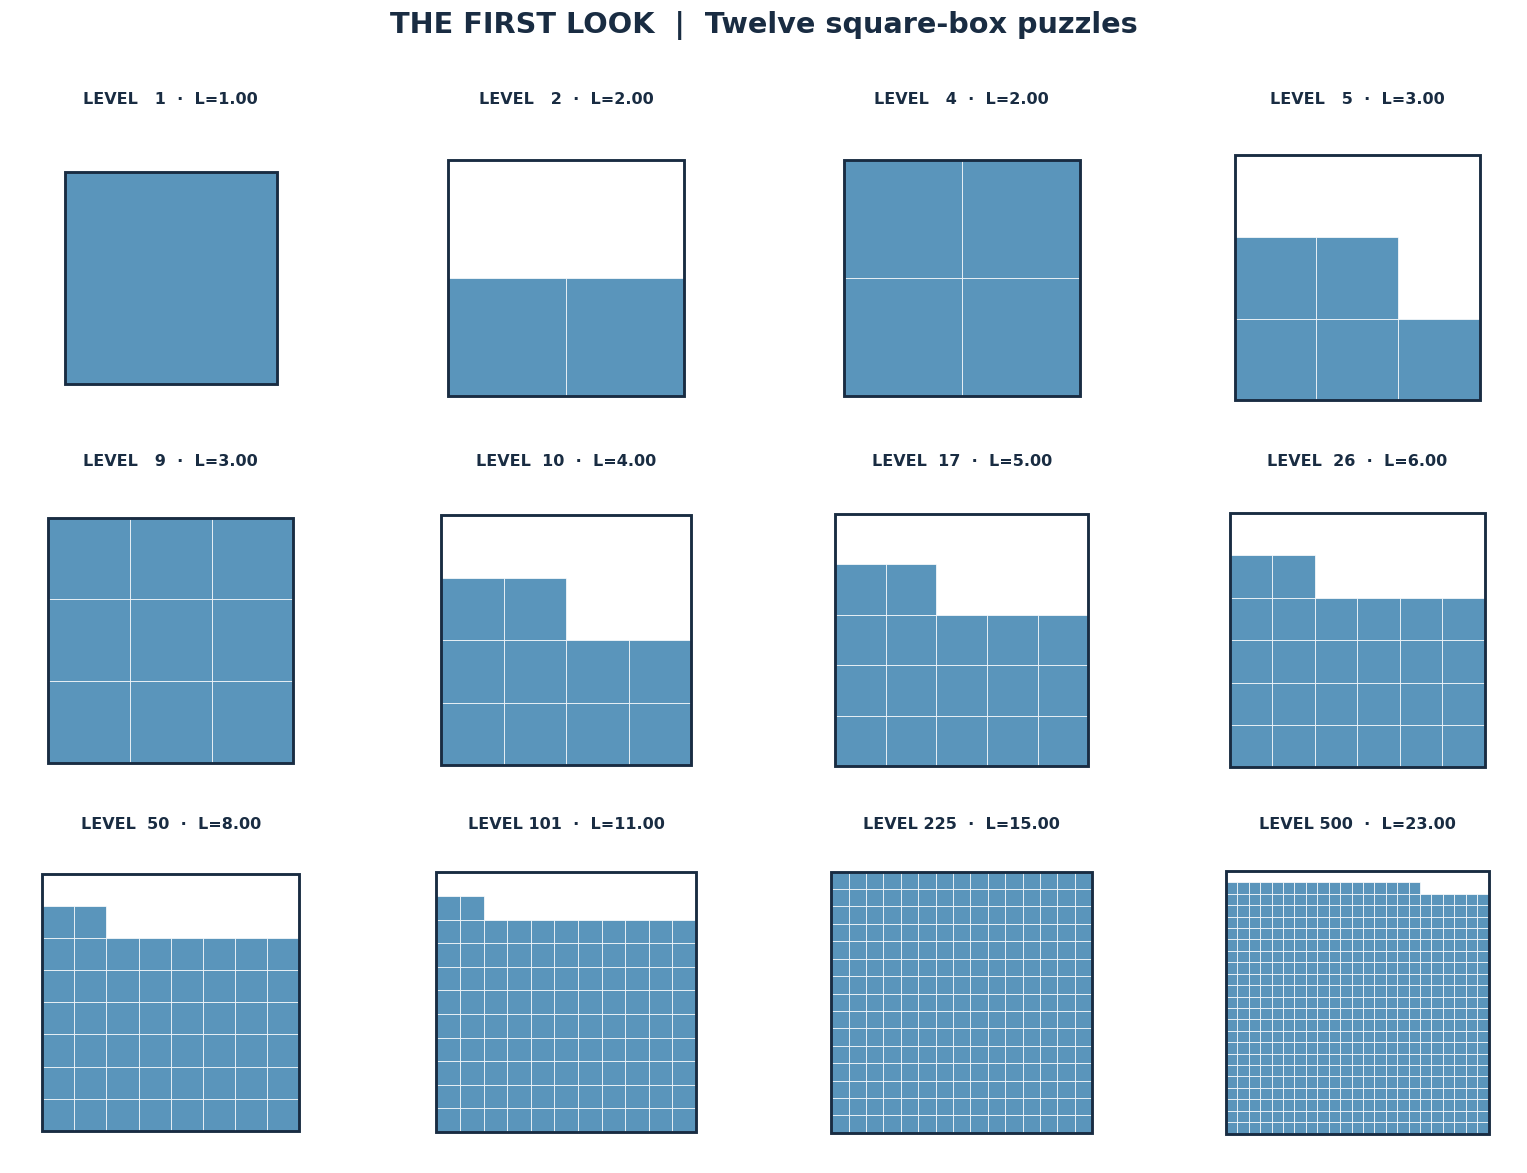

In [3]:
def corners(pack):
    """Unit-square corners from Nx3 (center_x, center_y, angle) rows."""
    pack = np.asarray(pack, dtype=float)
    base = np.array([[-.5, -.5], [.5, -.5], [.5, .5], [-.5, .5]])
    c, s = np.cos(pack[:, 2]), np.sin(pack[:, 2])
    rot = np.empty((len(pack), 2, 2))
    rot[:, 0, 0], rot[:, 0, 1] = c, -s
    rot[:, 1, 0], rot[:, 1, 1] = s, c
    return np.einsum("nij,kj->nki", rot, base) + pack[:, None, :2]


def side_length(pack):
    v = corners(pack)
    ranges = v.reshape(-1, 2)
    width, height = np.ptp(ranges, axis=0)
    return float(max(width, height))


def draw_pack(ax, pack, title="", color=BLUE, max_tiles=1000, labels=False):
    pack = np.asarray(pack)
    if len(pack) > max_tiles:
        raise ValueError("Too many tiles for this panel")
    verts = corners(pack)
    patches = [Polygon(poly, closed=True) for poly in verts]
    pc = PatchCollection(patches, facecolor=color, edgecolor="white", linewidth=.48, alpha=.93)
    ax.add_collection(pc)
    xy = verts.reshape(-1, 2)
    xmin, ymin = xy.min(axis=0)
    xmax, ymax = xy.max(axis=0)
    L = max(xmax-xmin, ymax-ymin)
    ax.add_patch(Rectangle((xmin, ymin), L, L, facecolor="none", edgecolor=INK, lw=1.8))
    ax.set_xlim(xmin-.1*L-.15, xmin+L+.1*L+.15)
    ax.set_ylim(ymin-.1*L-.15, ymin+L+.1*L+.15)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values(): spine.set_visible(False)
    ax.set_title(title, fontsize=10, pad=9)
    if labels and len(pack)<=10:
        for i,(x,y,_) in enumerate(pack):
            ax.text(x,y,str(i+1),ha="center",va="center",color=INK,fontsize=8,weight="bold")
    return L

samples = [1, 2, 4, 5, 9, 10, 17, 26, 50, 101, 225, 500]
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, n in zip(axes.flat, samples):
    p = raw.loc[raw.n.eq(n), ["x", "y", "angle"]].to_numpy()
    draw_pack(ax, p, f"LEVEL {n:>3}  ·  L={side_length(p):.2f}")
fig.suptitle("THE FIRST LOOK  |  Twelve square-box puzzles", fontsize=18, weight="bold", y=1.015)
plt.tight_layout(); plt.show()

**Finding 03.** The starter is visually clean — but the boxes immediately after `n = k²` often have conspicuous empty regions. That will create a very particular score pattern.

<a id="e04"></a>
## 04 · Measure the price of empty space

**Question.** How much space is left unused in each puzzle? The exact geometry matters: a rotated square may extend further than its center, so I compute the bounds from all **four corners**.

Grid baseline total score: 28.937669917
Zero-score puzzles: 31
Median occupancy: 95.56%


,L,density,waste,score
n,,,,
4,2.0,1.00000,0.0,0.00000
5,3.0,0.55556,4.0,0.34164
9,3.0,1.00000,0.0,0.00000
10,4.0,0.62500,6.0,0.26491
16,4.0,1.00000,0.0,0.00000
17,5.0,0.68000,8.0,0.21268
100,10.0,1.00000,0.0,0.00000
101,11.0,0.83471,20.0,0.09454
999,32.0,0.97559,25.0,0.01244


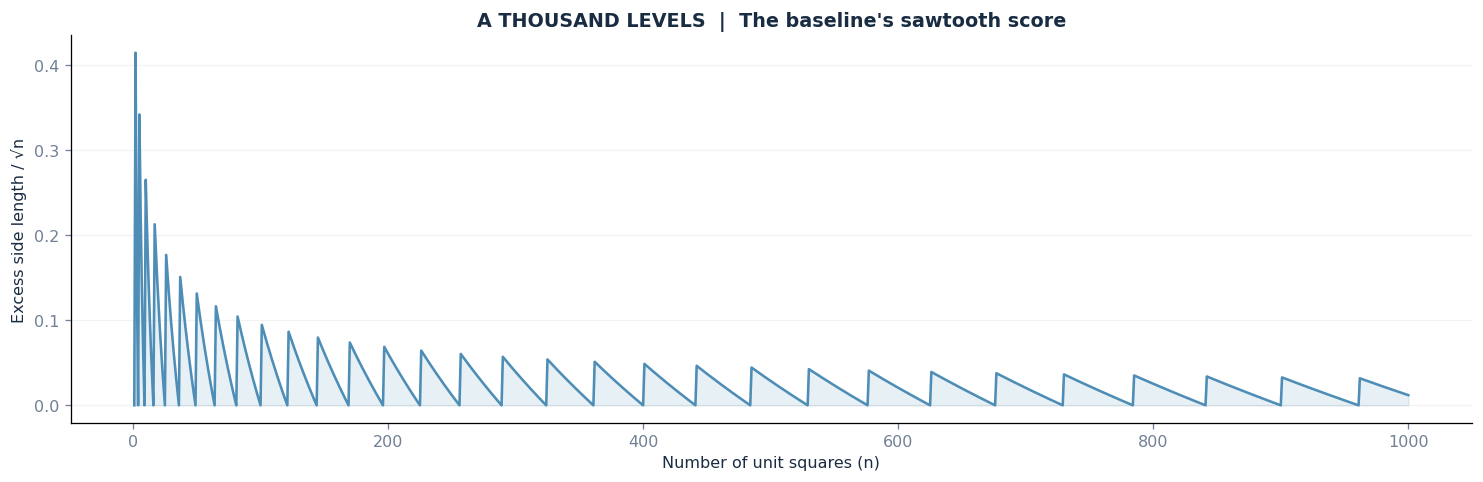

In [4]:
def metrics(df):
    a = df.angle.to_numpy(dtype=float)
    h = (np.abs(np.cos(a)) + np.abs(np.sin(a))) / 2
    d = df[["n"]].copy()
    d["xmin"] = df.x.to_numpy() - h
    d["xmax"] = df.x.to_numpy() + h
    d["ymin"] = df.y.to_numpy() - h
    d["ymax"] = df.y.to_numpy() + h
    g = d.groupby("n", sort=True).agg({"xmin":"min", "xmax":"max", "ymin":"min", "ymax":"max"})
    g["L"] = np.maximum(g.xmax-g.xmin, g.ymax-g.ymin)
    g["area"] = g.L**2
    g["density"] = g.index.to_numpy() / g.area
    g["waste"] = g.area - g.index.to_numpy()
    g["score"] = g.L / np.sqrt(g.index.to_numpy()) - 1
    return g

baseline = metrics(raw)
print(f"Grid baseline total score: {baseline.score.sum():.9f}")
print(f"Zero-score puzzles: {(np.abs(baseline.score)<1e-9).sum()}")
print(f"Median occupancy: {baseline.density.median():.2%}")
display(baseline.loc[[4,5,9,10,16,17,100,101,999,1000],["L","density","waste","score"]].round(5))
assert abs(baseline.score.sum()-28.93766991655) < 1e-6, "Unexpected starter geometry; investigate before optimizing"

fig, ax = plt.subplots(figsize=(13, 4.3))
ax.plot(baseline.index, baseline.score, color=BLUE, lw=1.6)
ax.fill_between(baseline.index.to_numpy(), baseline.score.to_numpy(), color=BLUE, alpha=.13)
ax.set(title="A THOUSAND LEVELS  |  The baseline's sawtooth score", xlabel="Number of unit squares (n)", ylabel="Excess side length / √n")
ax.grid(axis="y")
plt.tight_layout(); plt.show()

**Finding 04.** The sharp increases come from the grid: its width jumps by one unit when `n` passes a perfect square. Those jumps reveal which puzzle sizes are worth investigating.

<a id="e05"></a>
## 05 · The cliff after a perfect square

**Question.** Why does adding *one cookie* sometimes suddenly require a much bigger box? Compare `k²` to `k²+1` for every `k`.

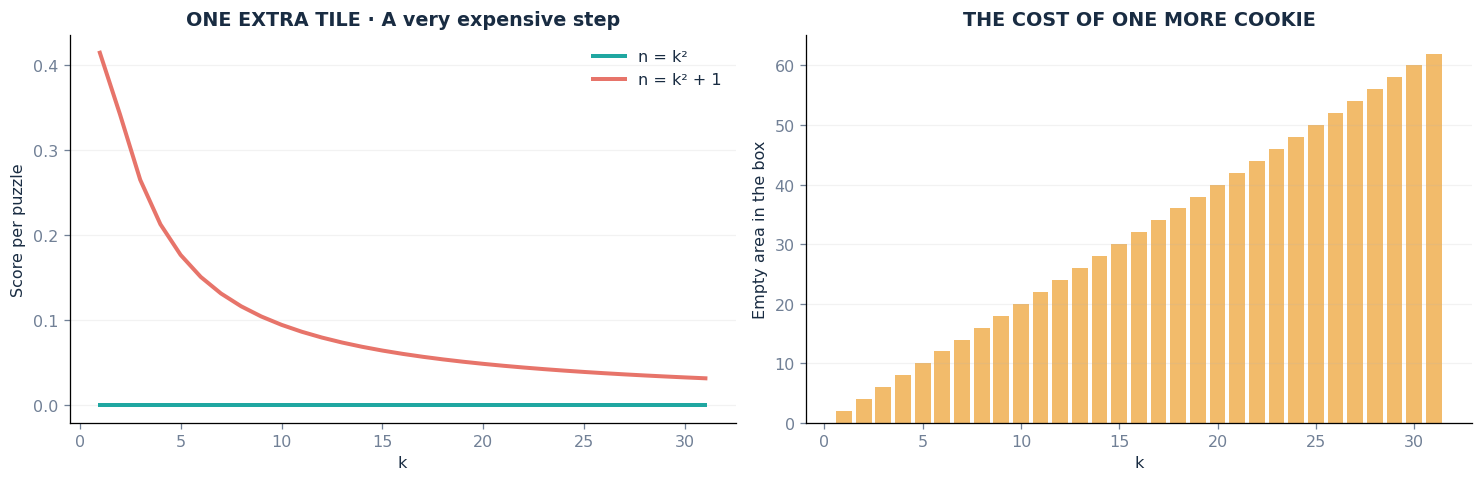

Largest absolute baseline score contributions:


,L,density,score
n,,,
2,2.0,0.50000,0.41421
5,3.0,0.55556,0.34164
10,4.0,0.62500,0.26491
6,3.0,0.66667,0.22474
17,5.0,0.68000,0.21268
11,4.0,0.68750,0.20605
18,5.0,0.72000,0.17851
26,6.0,0.72222,0.17670
3,2.0,0.75000,0.15470


In [5]:
ks = np.arange(1, 32)
a = baseline.loc[ks**2]
b = baseline.loc[ks**2 + 1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(ks, a.score, label="n = k²", color=TEAL, lw=2.5)
axes[0].plot(ks, b.score, label="n = k² + 1", color=RED, lw=2.5)
axes[0].set(xlabel="k", ylabel="Score per puzzle", title="ONE EXTRA TILE · A very expensive step")
axes[0].legend(frameon=False); axes[0].grid(axis="y")
axes[1].bar(ks, b.waste, color=GOLD, alpha=.9)
axes[1].set(xlabel="k", ylabel="Empty area in the box", title="THE COST OF ONE MORE COOKIE")
axes[1].grid(axis="y")
plt.tight_layout(); plt.show()
print("Largest absolute baseline score contributions:")
display(baseline.nlargest(12, "score")[["L", "density", "score"]].round(5))

**Finding 05.** The easiest baselines to criticize are `n = k²+1, k²+2, ...`: a full `(k+1)×(k+1)` box is purchased to hold only slightly more than `k²` objects. The next step is to make that jump **smaller than one full unit**.

<a id="e06"></a>
## 06 · A heatmap of all 1,000 levels

**Question.** Are inefficient levels isolated outliers, or do they form a repeating structure? Group each puzzle into the band `(k², (k+1)²]`.

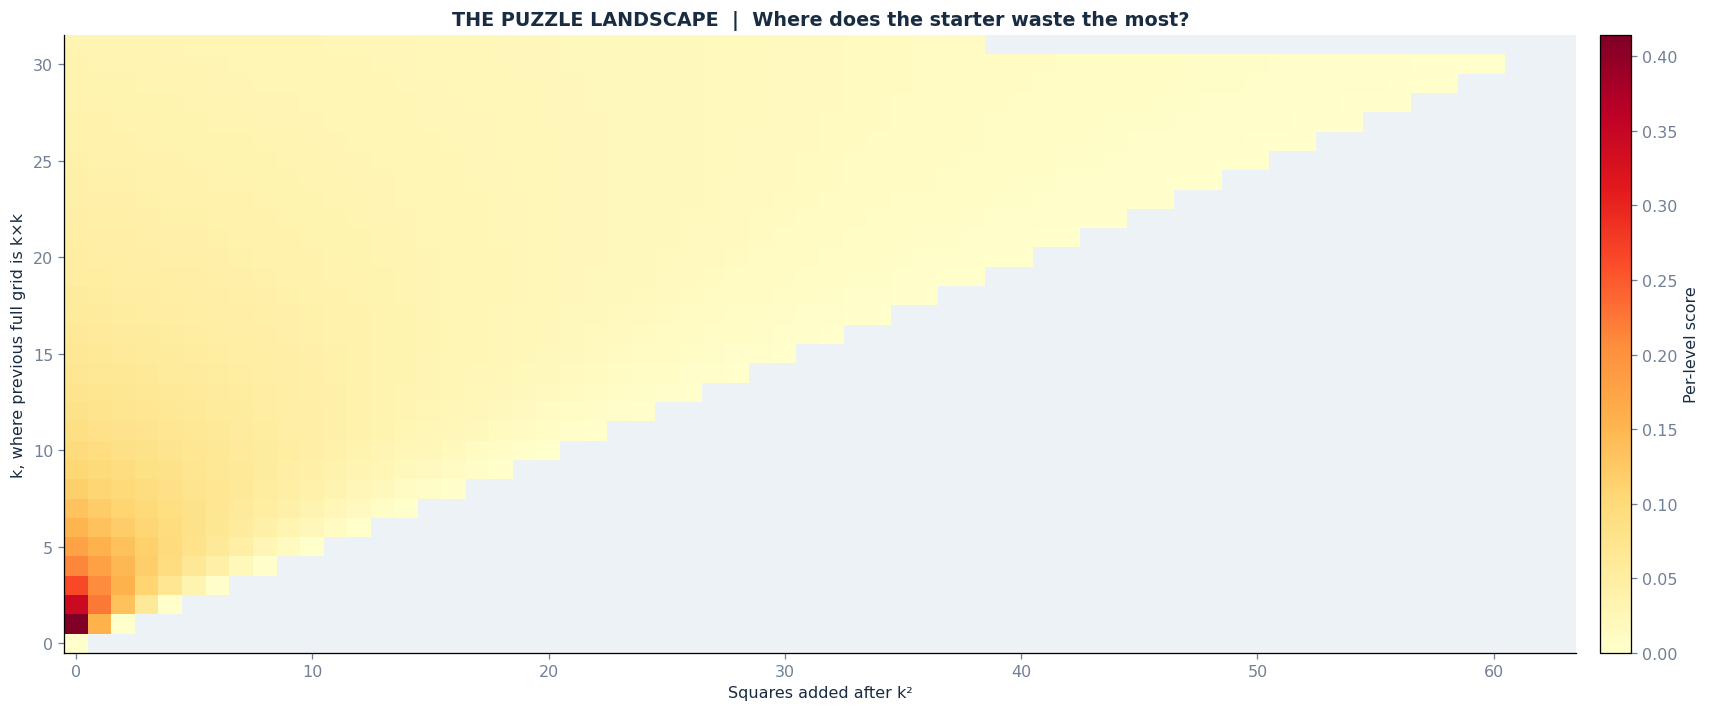

In [6]:
# 32 rows: band k, column: how many squares past k².
heat = np.full((32, 64), np.nan)
for n, val in baseline.score.items():
    k = math.isqrt(int(n)-1)
    r = int(n) - k*k
    if r<=64:
        heat[k, r-1] = val

fig, ax = plt.subplots(figsize=(15, 6.3))
cmap = plt.get_cmap("YlOrRd").copy(); cmap.set_bad("#EDF2F7")
im = ax.imshow(heat, origin="lower", aspect="auto", interpolation="nearest", cmap=cmap)
ax.set(xlabel="Squares added after k²", ylabel="k, where previous full grid is k×k",
       title="THE PUZZLE LANDSCAPE  |  Where does the starter waste the most?")
fig.colorbar(im, ax=ax, label="Per-level score", fraction=.025, pad=.015)
plt.tight_layout(); plt.show()

**Finding 06.** Waste clusters near the *start* of every new grid band. This is exactly where a special geometric construction can create gains across many different `n`, rather than solving one arbitrary puzzle at a time.

<a id="e07"></a>
## 07 · The five-cookie magic trick

**Question.** Can rotating just one unit square make a *provably smaller* box? Yes. I reconstruct the classical `n = 5` construction and compare it to the supplied grid.

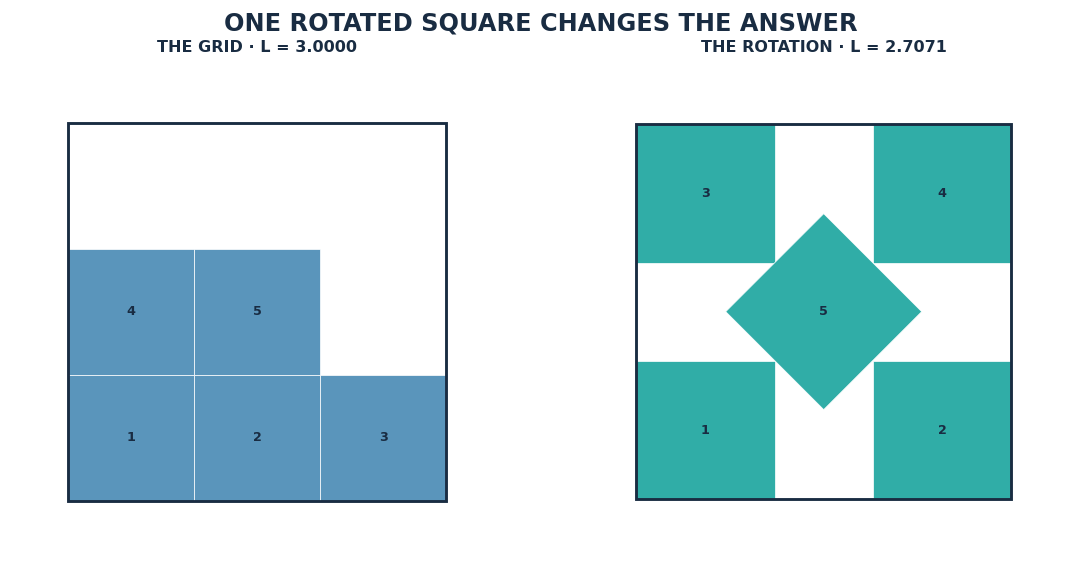

Side reduction: 0.292893
Score reduction: 0.130986


In [7]:
R = np.sqrt(2)/2

def five_cookie_pack():
    L = 2 + R
    return np.array([
        [0.5, 0.5, 0.0], [L-0.5, 0.5, 0.0],
        [0.5, L-0.5, 0.0], [L-0.5, L-0.5, 0.0],
        [L/2, L/2, np.pi/4],
    ], dtype=float)

original5 = raw.loc[raw.n.eq(5), ["x", "y", "angle"]].to_numpy()
improved5 = five_cookie_pack()
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
draw_pack(axes[0], original5, f"THE GRID · L = {side_length(original5):.4f}", BLUE, labels=True)
draw_pack(axes[1], improved5, f"THE ROTATION · L = {side_length(improved5):.4f}", TEAL, labels=True)
fig.suptitle("ONE ROTATED SQUARE CHANGES THE ANSWER", weight="bold", fontsize=15)
plt.tight_layout(); plt.show()
print("Side reduction:", round(3-side_length(improved5),6))
print("Score reduction:", round((3-side_length(improved5))/np.sqrt(5),6))

**Finding 07.** Turning a single cookie makes the enclosing square shorter by `1 − √2/2 ≈ 0.2929`. This is the classical optimal five-square construction (Göbel, 1979). But it reveals the central trick: **45° squares can exploit gaps a horizontal grid cannot**.

<a id="e08"></a>
## 08 · Who is touching whom?

**Question.** How can I check whether a visually tight layout is legal? For rotated squares, comparing centers is not enough. I use the **Separating Axis Theorem** (SAT), with neighboring candidate pairs found by a KD-tree.

Two convex polygons have disjoint interiors if *some* separating projection axis exists. Squares only need four distinct candidate axes (the two edge directions of each square).

In [8]:
def collision_audit(pack, tol=1e-9):
    """Return number of overlapping pairs (not contacts), and tested nearby pairs."""
    p = np.asarray(pack, dtype=float)
    if len(p) < 2:
        return 0, 0
    # Overlapping unit squares cannot have centers farther apart than sqrt(2).
    pairs = cKDTree(p[:, :2]).query_pairs(r=np.sqrt(2)+1e-7, output_type="ndarray")
    if len(pairs)==0:
        return 0, 0
    i,j = pairs[:,0],pairs[:,1]
    d = p[j,:2]-p[i,:2]
    ai,aj = p[i,2],p[j,2]
    gap = ai-aj
    other_half = .5*(np.abs(np.cos(gap))+np.abs(np.sin(gap)))
    limits = .5+other_half
    # Each candidate is a collision only if projections overlap on all four axes.
    axes = [
       np.column_stack((np.cos(ai),np.sin(ai))),
       np.column_stack((-np.sin(ai),np.cos(ai))),
       np.column_stack((np.cos(aj),np.sin(aj))),
       np.column_stack((-np.sin(aj),np.cos(aj))),
    ]
    overlap = np.ones(len(pairs),dtype=bool)
    for axis in axes:
        projection = np.abs(np.sum(d*axis,axis=1))
        overlap &= (projection < limits - tol)
    return int(overlap.sum()), int(len(pairs))

for name,p in [("Ordinary five",original5),("Rotated five",improved5)]:
    num,checked = collision_audit(p)
    print(f"{name:18s}: {num} collision(s) among {checked} nearby pairs")
assert collision_audit(improved5)[0] == 0

# A purposely invalid illustration: two squares are moved into each other.
invalid = improved5.copy(); invalid[4,:2] = invalid[0,:2]
print("Intentional collision test:", collision_audit(invalid))
assert collision_audit(invalid)[0] > 0

Ordinary five     : 0 collision(s) among 8 nearby pairs
Rotated five      : 0 collision(s) among 4 nearby pairs
Intentional collision test: (1, 1)


**Finding 08.** Legal *touching* and illegal *overlap* are different. The validator rejects the deliberately invalid example, but accepts the classical `n = 5` packing. This verifier will be reused before exporting anything.

<a id="e09"></a>
## 09 · Can one tiny trick scale to hundreds of levels?

**Question.** Is `n = 5` just a party trick? No: an old geometric idea is to divide the box into two regions of **axis-aligned squares**, separated by a **45° diagonal strip**. It can be constructed directly from integer arithmetic and geometry.

For an integer `k ≥ 3`, set `r = √2/2` and a container with `L = k+r`. Fill: (1) a lower-left triangular grid, (2) a shifted upper-right triangular grid, and (3) a diagonal chain of 45° unit squares.

The two triangles contain `k(k−1)` unrotated squares; the diagonal chain adds `⌊k√2⌋` squares. Thus the construction holds

\[N_k = k(k-1)+\lfloor k\sqrt2\rfloor = k^2+\lfloor(\sqrt2-1)k\rfloor\]

unit squares inside a box *narrower than `k+1`*. For any smaller `n`, extra tiles can be removed: removing objects never creates an overlap. This construction follows the classical diagonal-strip method described in the mathematical literature.

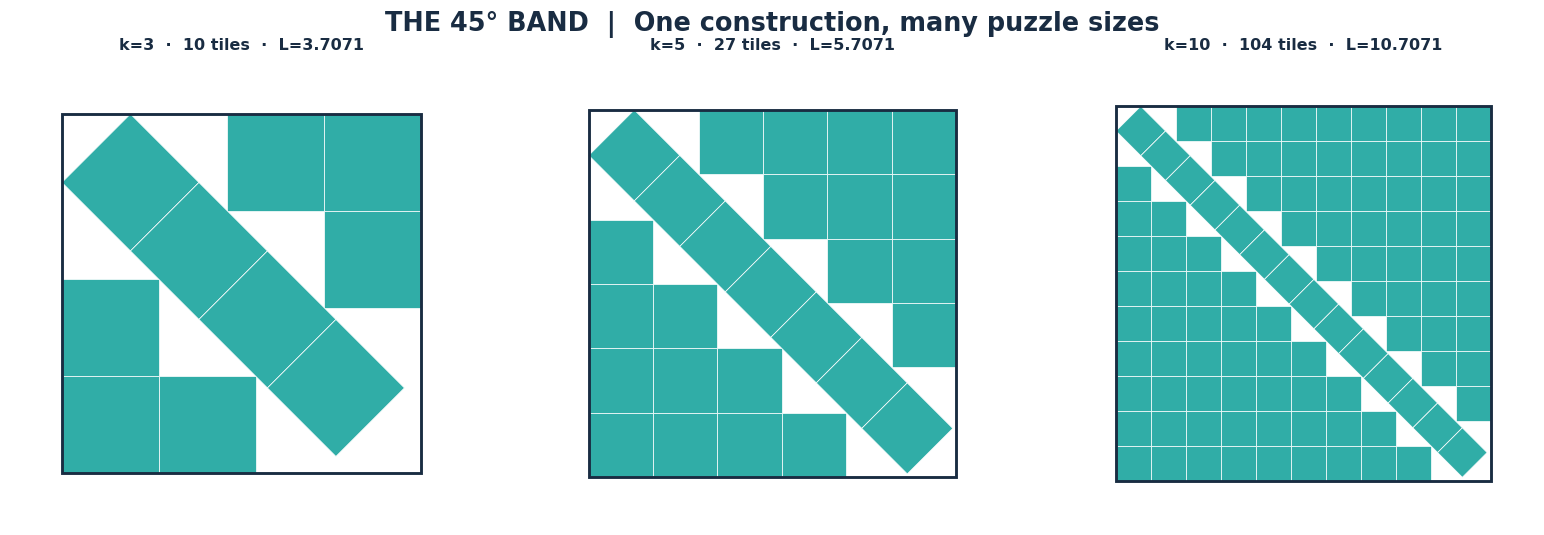

k= 3 :   10 squares, side=3.70710678, overlaps=0
k= 5 :   27 squares, side=5.70710678, overlaps=0
k=10 :  104 squares, side=10.70710678, overlaps=0
k=20 :  408 squares, side=20.70710678, overlaps=0
k=31 :  973 squares, side=31.70710678, overlaps=0


In [9]:
def diagonal_strip_pack(k):
    """Explicit exact-form construction, no fitting/model training/optimization."""
    assert isinstance(k, (int, np.integer)) and k >= 3
    r = np.sqrt(2)/2
    blocks = []
    # Lower-left and shifted upper-right triangular arrays of upright squares.
    for i in range(k):
        for j in range(k):
            if i+j <= k-2:
                blocks.append([i+.5,j+.5,0.0])
            elif i+j >= k:
                blocks.append([i+r+.5,j+r+.5,0.0])
    # Diamonds: parallel 45-degree squares sharing sides along the strip.
    diamonds = math.floor(k*np.sqrt(2)+1e-12)
    for t in range(diamonds):
        blocks.append([r+t*r, k-t*r, np.pi/4])
    pack = np.asarray(blocks, dtype=float)
    assert len(pack) == k*(k-1)+diamonds
    return pack

fig, axes = plt.subplots(1, 3, figsize=(14, 4.7))
for ax,k in zip(axes,[3,5,10]):
    pack = diagonal_strip_pack(k)
    draw_pack(ax,pack,f"k={k}  ·  {len(pack)} tiles  ·  L={side_length(pack):.4f}",TEAL)
fig.suptitle("THE 45° BAND  |  One construction, many puzzle sizes",fontsize=16,weight="bold")
plt.tight_layout(); plt.show()

for k in [3,5,10,20,31]:
    p=diagonal_strip_pack(k)
    assert collision_audit(p)[0] == 0, f"Diagonal layout collided at k={k}"
    print(f"k={k:2d} : {len(p):4d} squares, side={side_length(p):.8f}, overlaps=0")

**Finding 09.** A single deterministic formula gives valid non-grid arrangements at `k=3,5,10,20,31` (and the intermediate `k` values). This gives a *family of constructive upper bounds* from a single geometric recipe.

<a id="e10"></a>
## 10 · A diamond in the courtyard: a second packing family

**Question.** Can a tilted block improve puzzle sizes that the diagonal strip misses?

Imagine four **staircases of cookies** in the corners of a box. Between them sits a block of cookies tilted by 45°. Its interior is still made of ordinary, non-overlapping unit squares.

The classical *central tilted-block* construction appears in Friedman's [survey](https://erich-friedman.github.io/papers/squares/squares.html). I implement it in Python and explore a **rectangular tilted block** with `b × c` tiles between two pairs of corner staircases of sizes `a` and `d`.

For such a construction, the proposed bounding side is

\[
L=\max\left(a+1+\frac{b}{\sqrt2},\;d+1+\frac{c}{\sqrt2},\;a+d,\;\frac{b+c}{\sqrt2}\right),
\]

and the number of tiles is

\[
N=a(a+1)+d(d+1)+bc.
\]

These formulas define a family of candidate layouts. I plot several examples and check the geometry before accepting them.

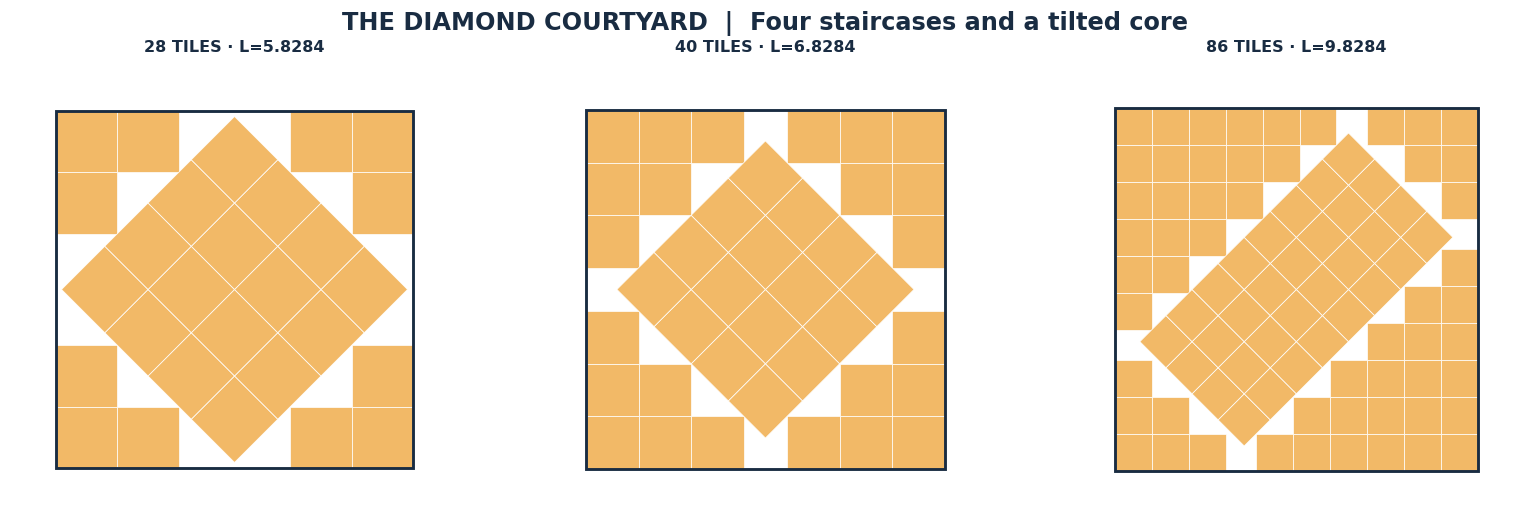

In [10]:
def courtyard_pack(a, d, b, c):
    """Four upright corner staircases + a rotated b-by-c block."""
    r = np.sqrt(0.5)
    L = max(a + 1 + b*r, d + 1 + c*r, a + d, (b+c)*r)
    tiles = []
    # Bottom-left and top-right corners: triangle with a rows.
    for i in range(a):
        for j in range(a-i):
            x, y = i + .5, j + .5
            tiles.extend(((x, y, 0), (L-x, L-y, 0)))
    # Top-left and bottom-right: triangle with d rows.
    for i in range(d):
        for j in range(d-i):
            x, y = i + .5, j + .5
            tiles.extend(((x, L-y, 0), (L-x, y, 0)))
    # Independent b × c lattice, all tiles rotated 45 degrees.
    for i in range(b):
        for j in range(c):
            u, v = i - (b-1)/2, j - (c-1)/2
            tiles.append((L/2 + (u-v)*r, L/2 + (u+v)*r, np.pi/4))
    pack = np.asarray(tiles, dtype=float)
    assert len(pack) == a*(a+1) + d*(d+1) + b*c
    return pack, L

examples = [(2, 2, 4, 4), (3, 3, 4, 4), (3, 6, 8, 4)]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, (a,d,b,c) in zip(axes, examples):
    p, expected_L = courtyard_pack(a,d,b,c)
    assert collision_audit(p)[0] == 0
    assert abs(side_length(p) - expected_L) < 1e-8
    draw_pack(ax, p, f"{len(p)} TILES · L={expected_L:.4f}", GOLD)
fig.suptitle("THE DIAMOND COURTYARD  |  Four staircases and a tilted core",
             fontsize=15, weight="bold")
plt.tight_layout(); plt.show()

**Finding 10.** One geometric recipe can create many valid alternatives. A square central block gives the classical construction; allowing `b` and `c` to differ offers more candidate sizes. A beautiful packing is only a **candidate** until the collision test passes.

<a id="e11"></a>
## 11 · The framing trick: turn one layout into a family

**Question.** Does every puzzle need a new construction? Not necessarily.

Once a packing fits in a square of side `L`, I can attach an **L-shaped border** of upright tiles along its top and right edges. A border of width `m` expands the side to `L + m` and adds exactly

\[
2m\lfloor L\rfloor+m^2
\]

new tiles. The original layout remains undisturbed. Removing surplus tiles also gives valid arrangements for smaller `n`.

This extension is a classical idea in square packing (see [Friedman's survey](https://erich-friedman.github.io/papers/squares/squares.html)). I use it to **compare thousands of small, deterministic geometric recipes**, selecting the smallest valid side for each level.

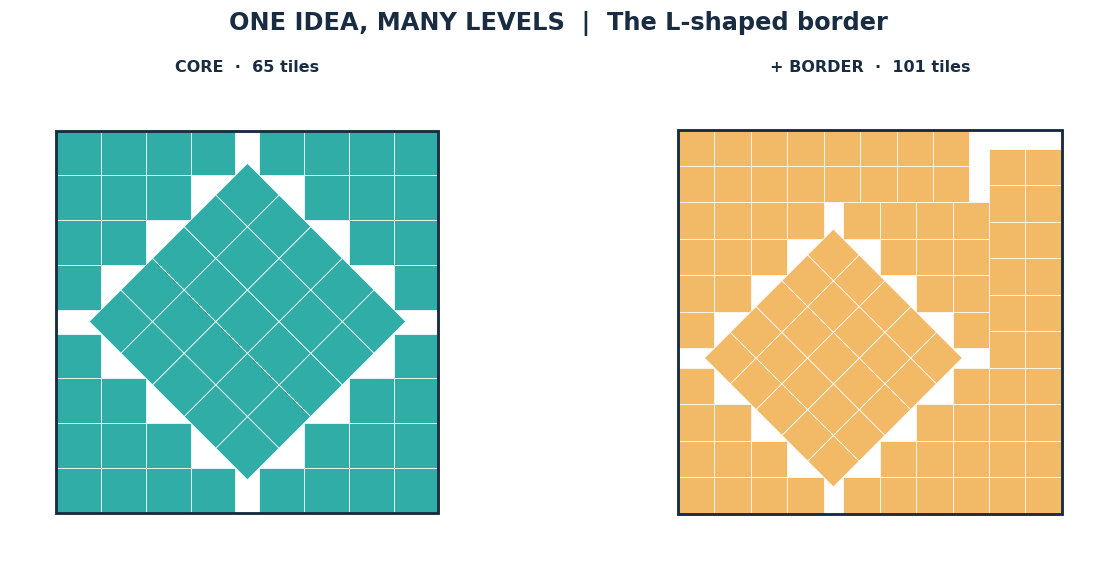

In [11]:
def add_l_border(pack, L, m):
    """Add m unit-width rows at the top and columns at the right."""
    if m == 0:
        return pack
    q = int(math.floor(L + 1e-10))
    border = []
    for x in range(q):
        for y in range(m):
            border.append((x+.5, L+y+.5, 0.0))
    for x in range(m):
        for y in range(q+m):
            border.append((L+x+.5, y+.5, 0.0))
    result = np.vstack([pack, np.asarray(border)])
    assert len(result) == len(pack) + 2*m*q + m*m
    return result

# A little gallery: the SAME courtyard, before and after extending the border.
core, core_L = courtyard_pack(4, 4, 5, 5)
framed = add_l_border(core, core_L, 2)
assert collision_audit(framed)[0] == 0
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
draw_pack(axes[0], core, f"CORE  ·  {len(core)} tiles", TEAL)
draw_pack(axes[1], framed, f"+ BORDER  ·  {len(framed)} tiles", GOLD)
fig.suptitle("ONE IDEA, MANY LEVELS  |  The L-shaped border", fontsize=15, weight="bold")
plt.tight_layout(); plt.show()

**Finding 11.** The border is not a search algorithm: it is a guaranteed way to **reuse** an already legal packing. Combining this with the diamond courtyard gives an entire library of reproducible candidate layouts .

<a id="e12"></a>
## 12 · A fair tournament: grid vs. diagonal vs. courtyard

**Question.** For each `n` from 1 to 1,000, which implemented construction fits into the smallest square?

I compare: **(1)** Kaggle's starting grid, **(2)** the diagonal strip from Experiment 09, and **(3)** the courtyard and its L-shaped border from Experiments 10–11. I keep the current layout unless the new candidate is strictly smaller.

The search compares explicit geometric constructions using the same container-size measure. Candidate layouts are generated and checked in the code.

In [12]:
# A candidate of size N works for every smaller n: discard extra tiles.
# Store only the shortest-side recipe for each candidate capacity.
by_capacity = [(float("inf"), None)] * 1001
R = np.sqrt(.5)

for a in range(1, 27):
    for d in range(1, 27):
        for b in range(max(1, round(a*np.sqrt(2))-12),
                       min(49, round(a*np.sqrt(2))+13)):
            for c in range(max(1, round(d*np.sqrt(2))-12),
                           min(49, round(d*np.sqrt(2))+13)):
                n0 = a*(a+1) + d*(d+1) + b*c
                L0 = max(a+1+b*R, d+1+c*R, a+d, (b+c)*R)
                if n0 > 1200 or L0 > 32 or n0 < L0*L0-2*L0:
                    continue  # Ignore very inefficient families.
                for m in range(34):
                    L = L0 + m
                    if L >= 32.01:
                        break
                    capacity = min(1000, n0 + 2*m*math.floor(L0+1e-10) + m*m)
                    if L < by_capacity[capacity][0]:
                        by_capacity[capacity] = (L, (a, d, b, c, m))

# Suffix minimum: pick the smallest container among recipes with capacity >= n.
recipe_for_n = [None] * 1001
best = (float("inf"), None)
for n in range(1000, 0, -1):
    if by_capacity[n][0] < best[0]:
        best = by_capacity[n]
    recipe_for_n[n] = best

submission = raw.copy()
changed = []
method_by_n = {}
cache = {}
SAFETY_EXPANSION = 1 + 1e-8

for n in range(1, 1001):
    grid_L = math.ceil(math.sqrt(n))
    choice = None
    method = None
    if n == 5:
        choice = five_cookie_pack()
        method = "five cookies"
    else:
        k = math.isqrt(n)
        if k >= 3 and k*k < n:
            capacity = k*(k-1) + math.floor(k*np.sqrt(2)+1e-12)
            if n <= capacity:
                choice = diagonal_strip_pack(k)[:n].copy()
                method = "diagonal"

    courtyard_L, recipe = recipe_for_n[n]
    current_L = grid_L if choice is None else min(grid_L, side_length(choice))
    if recipe is not None and courtyard_L < current_L - 1e-8:
        if recipe not in cache:
            a, d, b, c, m = recipe
            courtyard, L0 = courtyard_pack(a, d, b, c)
            cache[recipe] = add_l_border(courtyard, L0, m)
        choice = cache[recipe][:n].copy()
        method = "courtyard"

    if choice is None:
        continue
    choice[:, :2] *= SAFETY_EXPANSION  # Numerical cushion between touching tiles.
    if side_length(choice) >= grid_L - 1e-9:
        continue
    idx = submission.index[submission.n.eq(n)]
    ids = submission.loc[idx, "square_id"].to_numpy(dtype=int)
    submission.loc[idx, ["x", "y", "angle"]] = choice[ids]
    changed.append(n)
    method_by_n[n] = method

after = metrics(submission)
print(f"Puzzles improved: {len(changed):,} / 1,000")
print(pd.Series(method_by_n).value_counts().rename("puzzles"))
print(f"Original grid: {baseline.score.sum():.9f}")
print(f"Version 1:     25.664479312   (official Kaggle score)")
print(f"Version 2:     {after.score.sum():.9f}   (local estimate)")
print(f"Extra gain:    {25.664479312 - after.score.sum():.9f}")
assert after.score.sum() < 25.664479312
assert (after.L <= baseline.L + 1e-7).all()

/tmp/ipykernel_16/3480845696.py:70: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.         0.         0.         0.         0.78539816]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  submission.loc[idx, ["x", "y", "angle"]] = choice[ids]


Puzzles improved: 387 / 1,000
courtyard       309
diagonal         77
five cookies      1
Name: puzzles, dtype: int64
Original grid: 28.937669917
Version 1:     25.664479312   (official Kaggle score)
Version 2:     23.721594818   (local estimate)
Extra gain:    1.942884494


**Finding 12.** By selecting between geometric families, more levels improve than with a diagonal strip alone. The courtyard family is particularly useful where a new diagonal strip cannot fit enough tiles. 

<a id="e13"></a>
## 13 · Is symmetry making the box bigger?

**Question.** The tilted courtyards worked, but Experiment 12 searched a relatively narrow set of proportions. What if the best composition is surprisingly **lopsided**?

Think of the **gallery wall**: a large diagonal centerpiece does not always need four equally sized corners. Sometimes a tiny corner and a much larger opposite corner waste less wall space. I keep the same mathematical construction and test a wider set of **asymmetric proportions**. The experiment only changes the geometric parameters.

**The experiment:** expand the courtyard parameters, keep a candidate *only* when its actual bounding square is smaller than Version 2, and verify that its rotated tiles do not overlap.

V2 score:    23.721594818
V3 score:    23.432406505
Extra gain:  0.289188313
Newly improved puzzles: 154


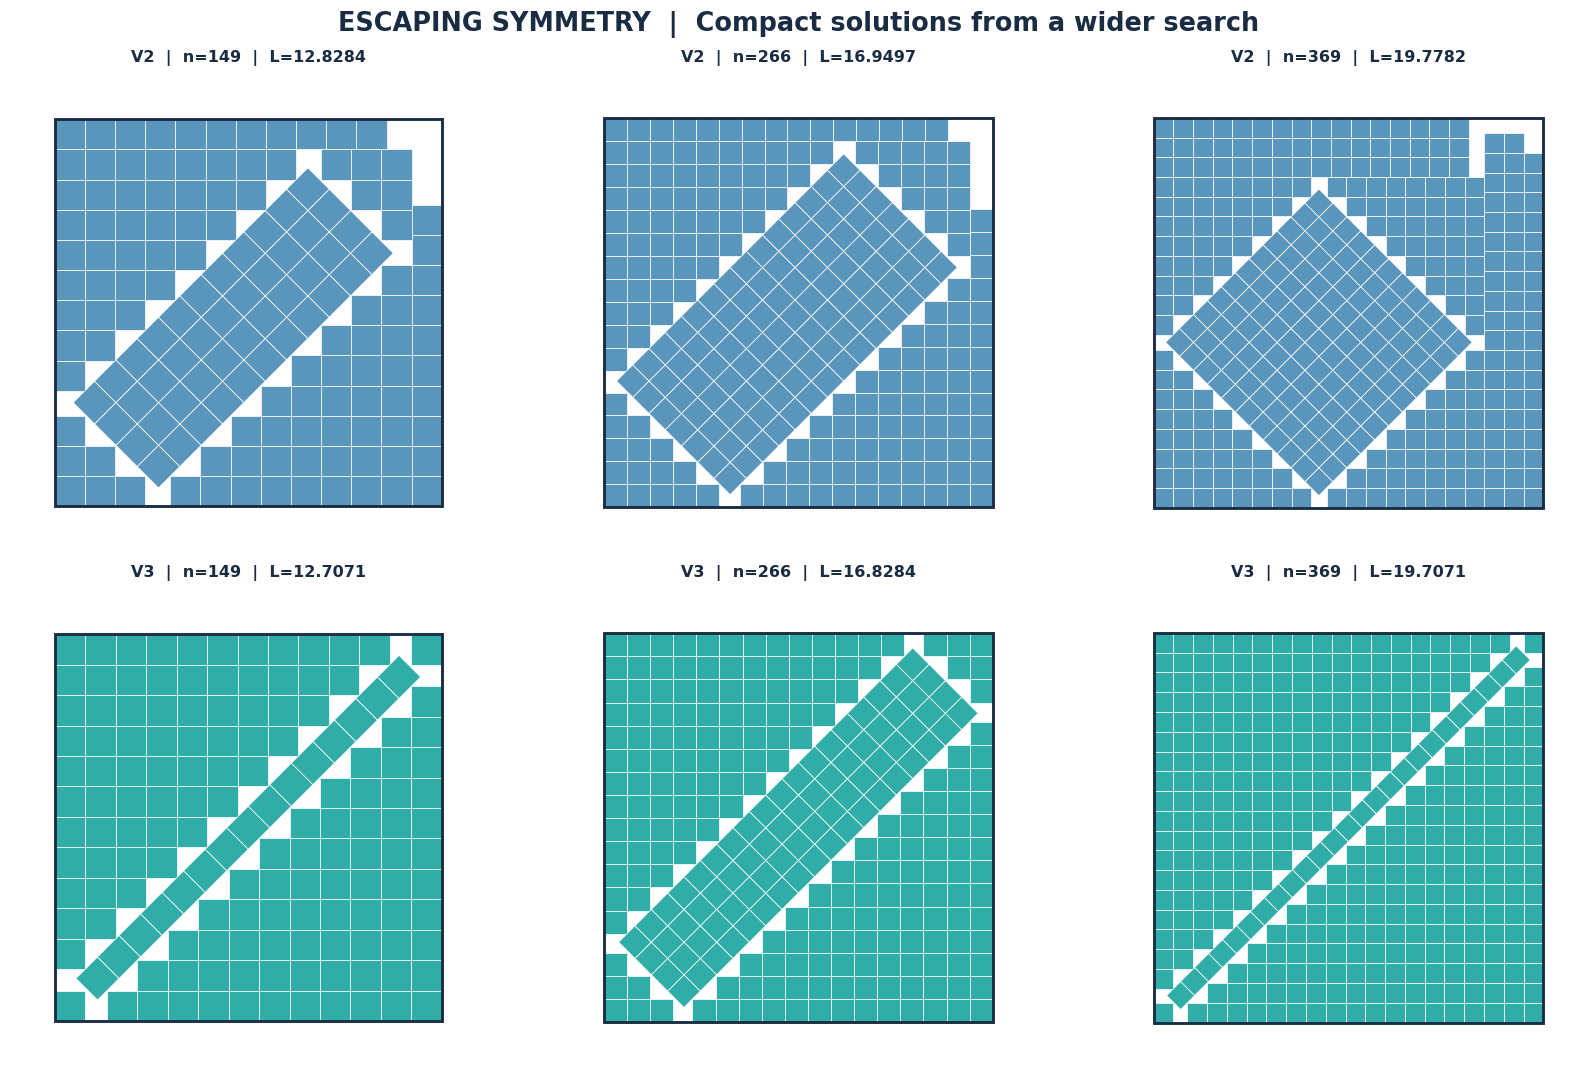

In [13]:
# A small, auditable upgrade to our own geometric search.
# V2 explored b ~= sqrt(2)*a and c ~= sqrt(2)*d (within +/-12).
# V3 allows stronger asymmetry, including an empty corner staircase.
v2_submission = submission.copy()
v2_metrics = after.copy()

wide_capacity = [(float("inf"), None)] * 1001
R = np.sqrt(.5)

for a in range(32):
    for d in range(32):
        for b in range(1, 66):
            for c in range(1, 66):
                n0 = a*(a+1) + d*(d+1) + b*c
                L0 = max(a+1+b*R, d+1+c*R, a+d, (b+c)*R)
                if n0 > 1200 or L0 > 32:
                    continue
                q = math.floor(L0 + 1e-10)
                for m in range(34):
                    L = L0 + m
                    if L >= 32.01:
                        break
                    capacity = min(1000, n0 + 2*m*q + m*m)
                    if L < wide_capacity[capacity][0]:
                        wide_capacity[capacity] = (L, (a,d,b,c,m))

# Any packing for N tiles is also a packing for n <= N after removing extras.
wide_recipes = [None] * 1001
best = (float("inf"), None)
for n in range(1000, 0, -1):
    if wide_capacity[n][0] < best[0]:
        best = wide_capacity[n]
    wide_recipes[n] = best

wide_cache = {}
newly_improved = []
for n in range(1, 1001):
    candidate_L, recipe = wide_recipes[n]
    if recipe is None or candidate_L >= after.loc[n, "L"] - 1e-7:
        continue
    if recipe not in wide_cache:
        a,d,b,c,m = recipe
        core, L0 = courtyard_pack(a,d,b,c)
        wide_cache[recipe] = add_l_border(core,L0,m)
    pack = wide_cache[recipe][:n].copy()
    pack[:,:2] *= SAFETY_EXPANSION
    if side_length(pack) >= after.loc[n, "L"] - 1e-9:
        continue
    collisions, tested = collision_audit(pack)
    if collisions:
        raise RuntimeError(f"Candidate n={n} has {collisions} overlaps")
    ix = submission.index[submission.n.eq(n)]
    ids = submission.loc[ix, "square_id"].to_numpy(dtype=int)
    submission.loc[ix,["x","y","angle"]] = pack[ids]
    newly_improved.append(n)
    method_by_n[n] = "asymmetric courtyard"
    if n not in changed:
        changed.append(n)

after = metrics(submission)
print("V2 score:   ",f"{v2_metrics.score.sum():.9f}")
print("V3 score:   ",f"{after.score.sum():.9f}")
print("Extra gain: ",f"{v2_metrics.score.sum()-after.score.sum():.9f}")
print("Newly improved puzzles:",len(newly_improved))
assert after.score.sum() < v2_metrics.score.sum()
assert (after.L <= v2_metrics.L + 1e-7).all()

# A genuine before/after gallery, not illustrative mock geometry.
examples_v3 = [149, 266, 369]
fig, axes = plt.subplots(2, 3, figsize=(14.5, 9.5))
for j,n in enumerate(examples_v3):
    before = v2_submission.loc[v2_submission.n.eq(n), ["x","y","angle"]].to_numpy()
    improved = submission.loc[submission.n.eq(n), ["x","y","angle"]].to_numpy()
    draw_pack(axes[0,j],before,f"V2  |  n={n}  |  L={side_length(before):.4f}",BLUE)
    draw_pack(axes[1,j],improved,f"V3  |  n={n}  |  L={side_length(improved):.4f}",TEAL)
fig.suptitle("ESCAPING SYMMETRY  |  Compact solutions from a wider search",fontsize=16,weight="bold")
plt.tight_layout();plt.show()


**Finding 13.** The same 45° courtyard construction improves further when I allow more uneven corner sizes and core proportions. The competition constraints are unchanged. Every accepted candidate is tested for overlaps; later I recheck **all** improved puzzles and the exported CSV. Even a simple parameter-range change can move the score when the geometry is nonconvex.

<a id="e14"></a>
## 14 · Four Corners, Four Decisions — The Gallery Wall Learns to Shift

**The question.** The previous courtyard treated opposite corners as mirror twins. Is that symmetry helping the geometry — or merely helping the programmer?

Imagine a gallery with four little clusters of paintings in the corners and a diagonal arrangement in the middle. If the north-west wall has room for one more painting than the south-east wall, keeping the central exhibition *exactly* centered is an unnecessary restriction.

Let the four corner staircase lengths be `a_sw`, `a_ne`, `d_nw`, `d_se`. A staircase of length `t` holds `t(t+1)/2` unit squares. The candidate capacity is

\[
N = T(a_{sw}) + T(a_{ne}) + T(d_{nw}) + T(d_{se}) + bc, \quad T(t)=\frac{t(t+1)}2.
\]

The rotated `b × c` courtyard is still made of **45° unit squares**. But instead of fixing its center at `(L/2, L/2)`, I shift it by

\[
(\Delta x,\Delta y) = \frac14\left(a_{sw}-a_{ne}+d_{nw}-d_{se},\quad a_{sw}-a_{ne}-d_{nw}+d_{se}\right).
\]

This is an extension of the earlier courtyard construction. The code builds each candidate and checks the resulting geometry.

19-square off-center candidate: L = 4.914214


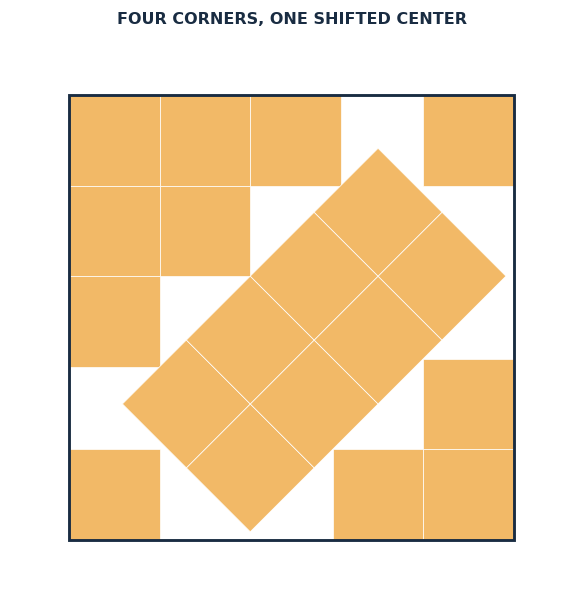

In [14]:
# 14 — An off-center courtyard with four independent corner staircases
# The final L is a conservative geometric envelope; numerical checks remain mandatory.
def offset_courtyard(a_sw, a_ne, d_nw, d_se, b, c):
    r = np.sqrt(0.5)
    da, dd = a_sw - a_ne, d_nw - d_se
    L = max(
        (a_sw + a_ne) / 2 + 1 + b*r,
        (d_nw + d_se) / 2 + 1 + c*r,
        max(a_sw, a_ne) + max(d_nw, d_se),
        (b + c)*r + (abs(da) + abs(dd))/2,
    )
    tiles = []
    for i in range(a_sw):
        for j in range(a_sw-i):
            tiles.append((i+.5, j+.5, 0))
    for i in range(a_ne):
        for j in range(a_ne-i):
            tiles.append((L-i-.5, L-j-.5, 0))
    for i in range(d_nw):
        for j in range(d_nw-i):
            tiles.append((i+.5, L-j-.5, 0))
    for i in range(d_se):
        for j in range(d_se-i):
            tiles.append((L-i-.5, j+.5, 0))

    shift_x, shift_y = (da+dd)/4, (da-dd)/4
    for i in range(b):
        for j in range(c):
            u, v = i-(b-1)/2, j-(c-1)/2
            tiles.append((L/2+shift_x+(u-v)*r,
                          L/2+shift_y+(u+v)*r, np.pi/4))
    result = np.asarray(tiles, dtype=float)
    assert len(result) == sum(t*(t+1)//2 for t in (a_sw,a_ne,d_nw,d_se)) + b*c
    return result, L

# A real candidate for 19 paintings. The asymmetry is small but meaningful.
example_pack, example_L = offset_courtyard(1, 1, 3, 2, 4, 2)
example_pack[:, :2] *= 1 + 1e-8
assert len(example_pack) == 19
assert collision_audit(example_pack)[0] == 0
print(f"19-square off-center candidate: L = {side_length(example_pack):.6f}")
fig, ax = plt.subplots(figsize=(5.6, 5.4))
draw_pack(ax, example_pack, "FOUR CORNERS, ONE SHIFTED CENTER", GOLD)
plt.tight_layout(); plt.show()

**Finding 14.** The four corners do not have to be mirror images. Changing one corner changes the **number of available tiles** and shifts the feasible position of the 45° center. A nice diagram alone does not qualify as an improvement: a candidate still needs a smaller measured `L` and zero overlapping interiors.

<a id="e15"></a>
## 15 · The Packing Auditions — Keep Only Verified Winners

**The question.** Does an asymmetric center help only a cute 19-square example, or does the idea scale across **1,000 puzzles**?

Instead of a general-purpose optimizer, I run a reproducible **bounded discrete search** over small changes to the existing courtyard's corner sizes. I score the candidate *capacity* first, then reconstruct each promising arrangement and explicitly reject candidates that are not valid or do not improve the **measured** bounding side.

The procedure is simple: generate a candidate, check it, and keep it only if the container becomes smaller.

In [15]:
# 15 — A bounded search for four independent staircase lengths.
# This is a geometry-only extension of Experiments 10 and 13.
v3_submission = submission.copy()
v3_metrics = after.copy()

new_capacity_L = np.full(1001, np.inf)
new_capacity_recipe = [None] * 1001
r = np.sqrt(.5)

for a in range(32):
    for d in range(32):
        for da in range(-3, 4):
            a_sw, a_ne = a + max(da, 0), a + min(da, 0)
            if min(a_sw, a_ne) < 0 or max(a_sw, a_ne) > 32:
                continue
            for dd in range(-3, 4):
                d_nw, d_se = d + max(dd, 0), d + min(dd, 0)
                if min(d_nw, d_se) < 0 or max(d_nw, d_se) > 32:
                    continue
                mean_a, mean_d = (a_sw+a_ne)/2, (d_nw+d_se)/2
                blo = max(1, int(mean_a*np.sqrt(2))-11)
                bhi = min(64, int(mean_a*np.sqrt(2))+14)
                clo = max(1, int(mean_d*np.sqrt(2))-11)
                chi = min(64, int(mean_d*np.sqrt(2))+14)
                B, C = np.meshgrid(np.arange(blo, bhi+1),
                                   np.arange(clo, chi+1), indexing="ij")
                if B.size == 0:
                    continue
                candidate_L = np.maximum.reduce(np.broadcast_arrays(
                    mean_a + 1 + B*r,
                    mean_d + 1 + C*r,
                    np.full(B.shape, max(a_sw,a_ne) + max(d_nw,d_se)),
                    (B+C)*r + (abs(a_sw-a_ne)+abs(d_nw-d_se))/2,
                ))
                candidate_N = (sum(t*(t+1)//2 for t in
                          (a_sw,a_ne,d_nw,d_se)) + B*C)
                plausible = ((candidate_N <= 1200) & (candidate_L <= 32) &
                             (candidate_N >= candidate_L**2 - 2*candidate_L - 25))
                for i, j in np.argwhere(plausible):
                    b, c = int(B[i,j]), int(C[i,j])
                    L0, n0 = float(candidate_L[i,j]), int(candidate_N[i,j])
                    if n0 <= 0:
                        continue
                    q = math.floor(L0+1e-9)
                    for m in range(int(32-L0)+1):
                        cap = min(1000, n0 + 2*m*q + m*m)
                        if L0+m < new_capacity_L[cap]:
                            new_capacity_L[cap] = L0+m
                            new_capacity_recipe[cap] = (a_sw,a_ne,d_nw,d_se,b,c,m)

# A recipe with N squares may solve any puzzle n <= N by deleting extra tiles.
new_for_n = [None]*1001
best_L, best_recipe = np.inf, None
for n in range(1000, 0, -1):
    if new_capacity_L[n] < best_L:
        best_L, best_recipe = new_capacity_L[n], new_capacity_recipe[n]
    new_for_n[n] = (best_L, best_recipe)

new_count = 0
new_rejected = 0
new_cache = {}
new_sizes = []
for n in range(1, 1001):
    estimated_L, recipe = new_for_n[n]
    if recipe is None or estimated_L >= v3_metrics.loc[n,"L"]-1e-8:
        continue
    if recipe not in new_cache:
        a_sw,a_ne,d_nw,d_se,b,c,m = recipe
        pack,L0 = offset_courtyard(a_sw,a_ne,d_nw,d_se,b,c)
        new_cache[recipe] = add_l_border(pack,L0,m)
    candidate = new_cache[recipe][:n].copy()
    candidate[:,:2] *= SAFETY_EXPANSION
    if side_length(candidate) >= v3_metrics.loc[n,"L"]-1e-8:
        new_rejected += 1
        continue
    overlaps, _ = collision_audit(candidate)
    if overlaps:
        new_rejected += 1
        continue
    rows = submission.index[submission.n.eq(n)]
    ids = submission.loc[rows,"square_id"].to_numpy(dtype=int)
    submission.loc[rows,["x","y","angle"]] = candidate[ids]
    method_by_n[n] = "offset courtyard"
    if n not in changed:
        changed.append(n)
    new_count += 1
    new_sizes.append(n)

after = metrics(submission)
print(f"V3 reference:    {v3_metrics.score.sum():.9f}")
print(f"V6 / local estimate:    {after.score.sum():.9f}")
print(f"New accepted puzzles:   {new_count}")
print(f"Rejected candidates:    {new_rejected}")
print(f"Gain from this chapter: {v3_metrics.score.sum()-after.score.sum():.9f}")
assert new_count > 0
assert after.score.sum() < v3_metrics.score.sum()
assert (after.L <= v3_metrics.L + 1e-7).all()

V3 reference:    23.432406505
V6 / local estimate:    23.205993706
New accepted puzzles:   96
Rejected candidates:    183
Gain from this chapter: 0.226412800


**Finding 15.** A small, independently auditable extension improves **more puzzles without changing any of the earlier geometry families**. I retain improvements only after checking both the bounding box and potential square overlaps.

<a id="e16"></a>
## 16 · The Gallery Before and After — Where Did the Space Go?

A new algorithm is not a good EDA chapter without **showing what changed**. The following panels use the actual coordinates from the earlier V3 solution and the newly selected solution for the same puzzle size. Both rows show actual square coordinates.

I also inspect the *per-level* score difference. A small total improvement spread over many levels is often more robust than one spectacular-looking example.

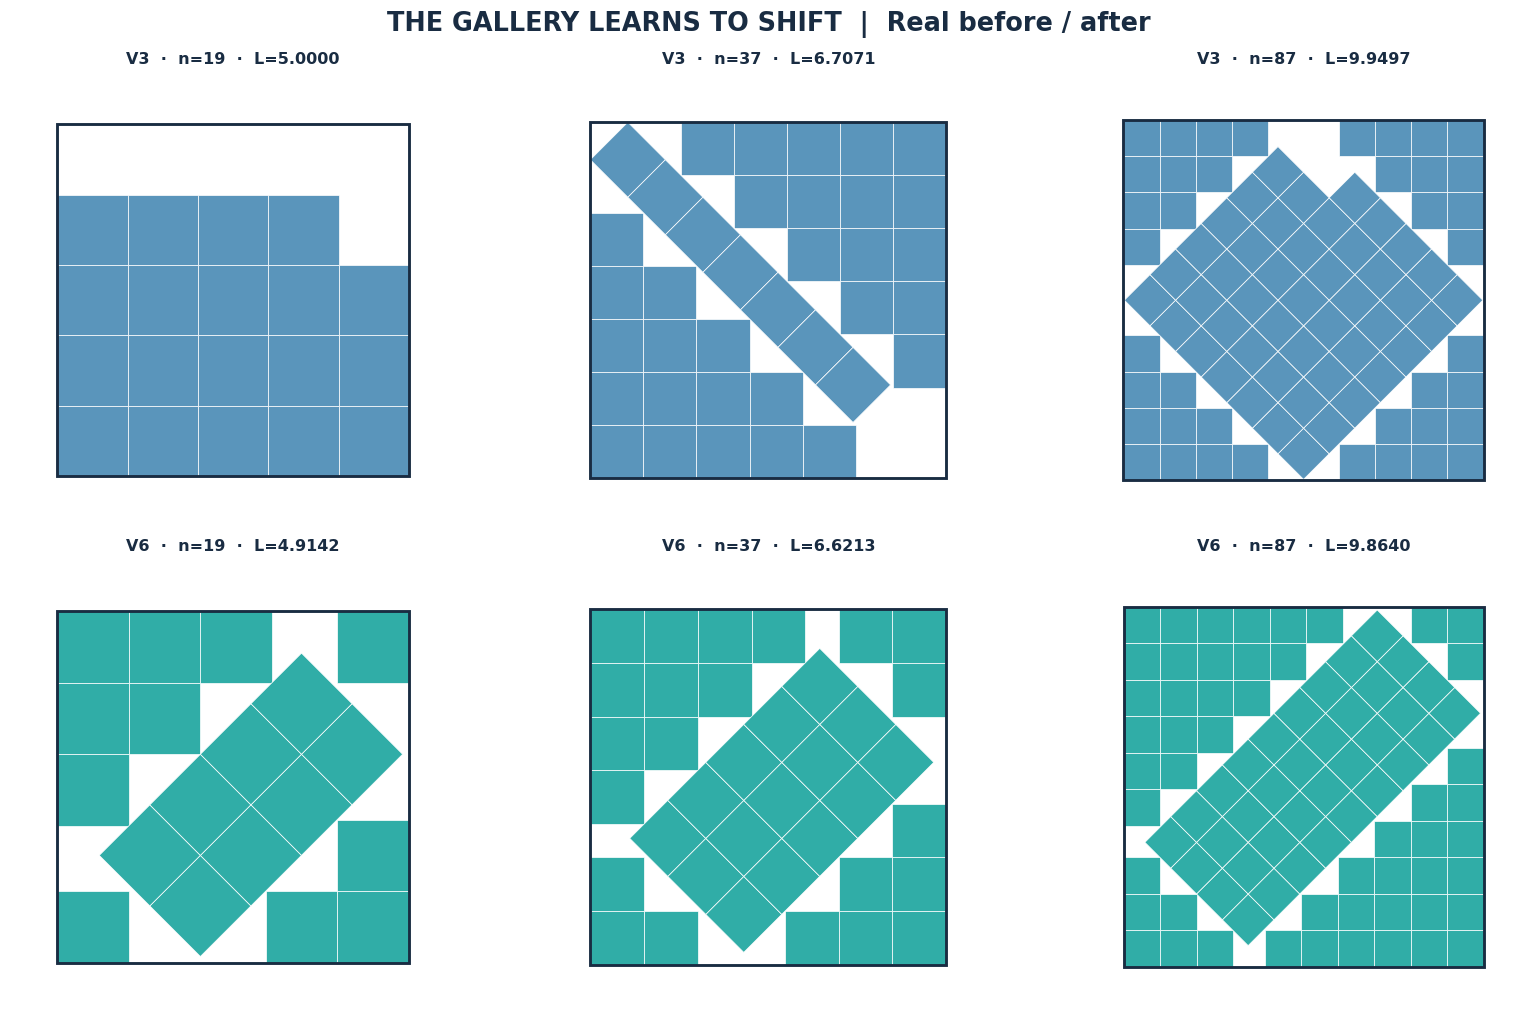

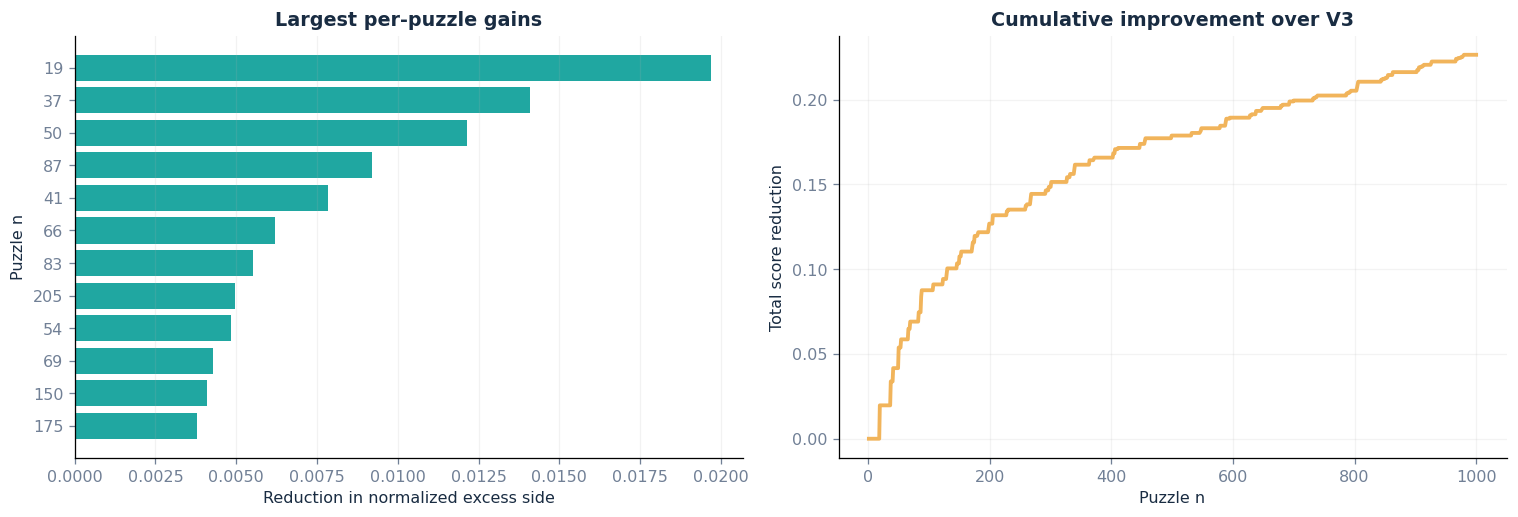

,previous,new,gain,old_L,new_L
n,,,,,
19,0.147079,0.127398,0.019681,5.000000,4.914214
37,0.102642,0.088538,0.014103,6.707107,6.621320
50,0.089950,0.077817,0.012132,7.707107,7.621320
87,0.066725,0.057528,0.009197,9.949748,9.863961
41,0.093216,0.085368,0.007848,7.000000,6.949748
66,0.071771,0.065585,0.006186,8.707107,8.656854
83,0.065493,0.059977,0.005516,9.707107,9.656854
205,0.040626,0.035662,0.004964,14.899495,14.828427
54,0.081824,0.076988,0.004836,7.949748,7.914214


In [16]:
# 16 — Real V3 vs V6 comparisons and an audit-friendly improvement leaderboard
comparison = pd.DataFrame({
    "previous": v3_metrics.score,
    "new": after.score,
    "gain": v3_metrics.score-after.score,
    "old_L": v3_metrics.L,
    "new_L": after.L,
})
examples = [19, 37, 87]
fig, axes = plt.subplots(2,3, figsize=(14.2, 9.0))
for col, n in enumerate(examples):
    before = v3_submission.loc[v3_submission.n.eq(n), ["x","y","angle"]].to_numpy()
    now = submission.loc[submission.n.eq(n), ["x","y","angle"]].to_numpy()
    assert comparison.loc[n,"gain"] > 0, f"No improvement for illustrated n={n}"
    draw_pack(axes[0,col], before, f"V3  ·  n={n}  ·  L={side_length(before):.4f}", BLUE)
    draw_pack(axes[1,col], now, f"V6  ·  n={n}  ·  L={side_length(now):.4f}", TEAL)
fig.suptitle("THE GALLERY LEARNS TO SHIFT  |  Real before / after", fontsize=16, weight="bold")
plt.tight_layout();plt.show()

fig, axes = plt.subplots(1,2,figsize=(13.3,4.6))
top = comparison.nlargest(12,"gain").sort_values("gain")
axes[0].barh(top.index.astype(str), top.gain, color=TEAL)
axes[0].set(title="Largest per-puzzle gains", xlabel="Reduction in normalized excess side", ylabel="Puzzle n")
axes[0].grid(axis="x",alpha=.16)
axes[1].plot(comparison.index, comparison.gain.cumsum(), color=GOLD, lw=2.4)
axes[1].set(title="Cumulative improvement over V3", xlabel="Puzzle n", ylabel="Total score reduction")
axes[1].grid(alpha=.15)
plt.tight_layout();plt.show()

display(comparison.nlargest(12,"gain").round(6))

**Finding 16.** The better solution is not necessarily the more symmetrical-looking one. With the **same exact number of squares**, a subtly shifted diagonal courtyard can remove some of the otherwise wasted margin. The numerical gains and the images agree — and the final full-file audit still follows below.

<a id="e17"></a>
## 17 · A Rectangle Hiding in a Square — The Side-Strip Trick

**The question.** The courtyard layouts always started inside a square. Could a **non-square core** become a better square packing after adding one narrow column?

Imagine the **Gallery Wall**: the paintings first fill a tall rectangular wall, then a one-tile-wide strip is attached alongside it. The final wall becomes square — and can sometimes hold more paintings with less empty space than the earlier courtyard.

This is a classical idea from [Erich Friedman’s square-packing survey, §3 / Figure 9](https://erich-friedman.github.io/papers/squares/squares.html), inspired by Göbel’s tilted-core constructions. I reconstruct the published geometry, explore the parameters, and compare the verified packings with V6.

Verified rectangle recipes: 32
Improved levels: 44
Current local score: 23.123544005


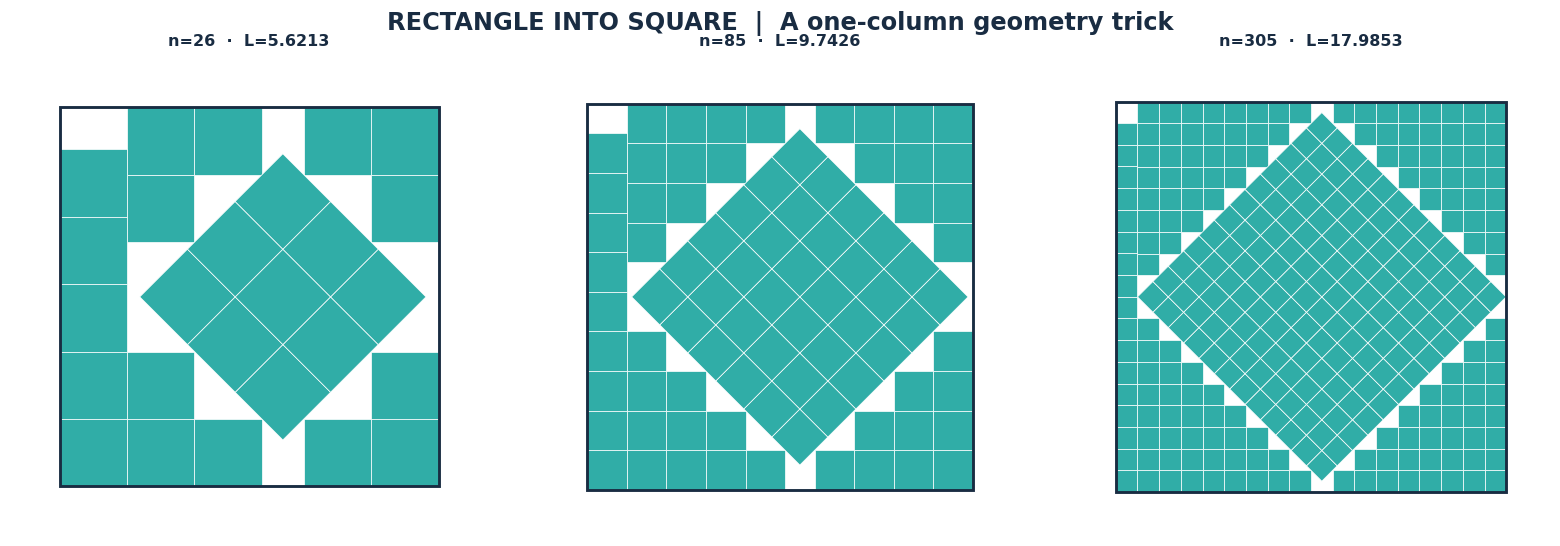

In [17]:
# 17 — Classical off-centre rectangle + one-column refill (Friedman / Göbel)
# Generalize a known construction across n=1..1000, without external Kaggle datasets.
v6_snapshot = submission.copy()
v6_metrics = after.copy()


def rectangular_gallery(a, b):
    """Four corner staircases + b×b diamond core + one upright side column.

    A special case of the rectangle-to-square packing in Friedman's 2009 survey.
    The construction is numerical; we verify every accepted packing with SAT.
    """
    r = np.sqrt(.5)
    W = a + .5 + b*r
    L = a + 1.5 + b*r   # rectangular core is W by L, plus a 1-wide column
    squares = []
    for i in range(a):
        for j in range(a-i):
            x, y = i+.5, j+.5
            squares.extend(((x+1,y,0), (W-x+1,L-y,0),
                            (x+1,L-y,0), (W-x+1,y,0)))
    for i in range(b):
        for j in range(b):
            u, v = i-(b-1)/2, j-(b-1)/2
            squares.append((1+W/2+(u-v)*r, L/2+(u+v)*r, np.pi/4))
    for j in range(math.floor(L+1e-10)):
        squares.append((.5, j+.5, 0))
    return np.asarray(squares,dtype=float), L

# The straightforward case n=26 is a wonderful geometric illustration.
example_rect, L_rect = rectangular_gallery(2,3)
assert len(example_rect)==26
assert collision_audit(example_rect)[0]==0
assert np.isclose(side_length(example_rect), 3.5+3*np.sqrt(.5), atol=1e-9)

# Bounded recipe search, same rules for every puzzle.
rect_recipes=[]
for a in range(1,27):
    for b in range(1,48):
        n0 = 2*a*(a+1) + b*b + math.floor(a+1.5+b/np.sqrt(2)+1e-10)
        L0 = a+1.5+b/np.sqrt(2)
        if n0 < 5 or n0 > 1030 or L0 >= 32: continue
        for m in range(max(0,int(32-L0))+1):
            L = L0+m
            cap = min(1000,n0+2*m*math.floor(L0+1e-10)+m*m)
            # Fast check: don't build arrangements that cannot beat the V6 envelope.
            if np.any(v6_metrics.L.to_numpy()[:cap] > L+1e-7):
                rect_recipes.append((L,cap,a,b,m))

rectangle_gains={}
valid_rectangles=0
rect_cache={}
for predicted_L,cap,a,b,m in sorted(rect_recipes):
    if not np.any(after.L.to_numpy()[:cap] > predicted_L+1e-7):
        continue
    recipe=(a,b,m)
    if recipe not in rect_cache:
        core,L0=rectangular_gallery(a,b)
        if collision_audit(core)[0] != 0:continue
        complete=add_l_border(core,L0,m)
        if collision_audit(complete)[0] != 0:continue
        rect_cache[recipe]=complete
        valid_rectangles+=1
    complete=rect_cache[recipe]
    for n in range(1,min(cap,len(complete))+1):
        if predicted_L >= after.loc[n,'L'] - 1e-7:continue
        pack=complete[:n].copy()
        pack[:,:2]*=SAFETY_EXPANSION
        L=side_length(pack)
        if L >= after.loc[n,'L'] - 1e-7:continue
        if collision_audit(pack)[0]!=0:continue
        ids=submission.loc[submission.n.eq(n),'square_id'].to_numpy(dtype=int)
        rows=submission.index[submission.n.eq(n)]
        submission.loc[rows,['x','y','angle']]=pack[ids]
        if n not in changed:changed.append(n)
        method_by_n[n]='rectangle + side strip'
        rectangle_gains[n]=(float(v6_metrics.loc[n,'L']-L))/np.sqrt(n)
        # Refresh individual lower envelope for the next recipe.
        after.loc[n,'L']=L

after=metrics(submission)
print('Verified rectangle recipes:',valid_rectangles)
print('Improved levels:',len(rectangle_gains))
print('Current local score:',f'{after.score.sum():.9f}')
assert after.score.sum() < v6_metrics.score.sum()

fig,axes=plt.subplots(1,3,figsize=(14.0,4.8))
for ax,n in zip(axes,[26,85,305]):
    p=submission.loc[submission.n.eq(n),['x','y','angle']].to_numpy()
    draw_pack(ax,p,f'n={n}  ·  L={side_length(p):.4f}',TEAL)
fig.suptitle('RECTANGLE INTO SQUARE  |  A one-column geometry trick',fontsize=15,weight='bold')
plt.tight_layout();plt.show()


**Finding 17.** The rectangle-to-square construction improves a family of levels, rather than one isolated puzzle. The parameter sweep shows where this published construction improves on the previous version. Each improvement survives a numerical separating-axis collision check.

<a id="e18"></a>
## 18 · Breaking the 45° Habit — Walter Trump’s Eleven Squares

**The question.** Most earlier layouts use 0° and 45°. Is 45° actually the best angle for a tilted packing?

**No.** In 1979, Walter Trump found an 11-square layout with **six upright squares and five tilted at approximately 40.182°**. Its container side is approximately **3.87708359**, versus **4** for the grid. This is now a mathematically established optimum, not a heuristic. The exact coordinate relationships are documented by the [Squares Project](https://squaremath.org/cases/11.html) and discussed in [Friedman’s survey](https://erich-friedman.github.io/papers/squares/squares.html).

In the **Cookie Box** analogy: sometimes the last improvement comes not from adding a bigger box, but from rotating five cookies by a *surprisingly precise* angle. I reconstruct the published geometry numerically and check for overlaps before using it.

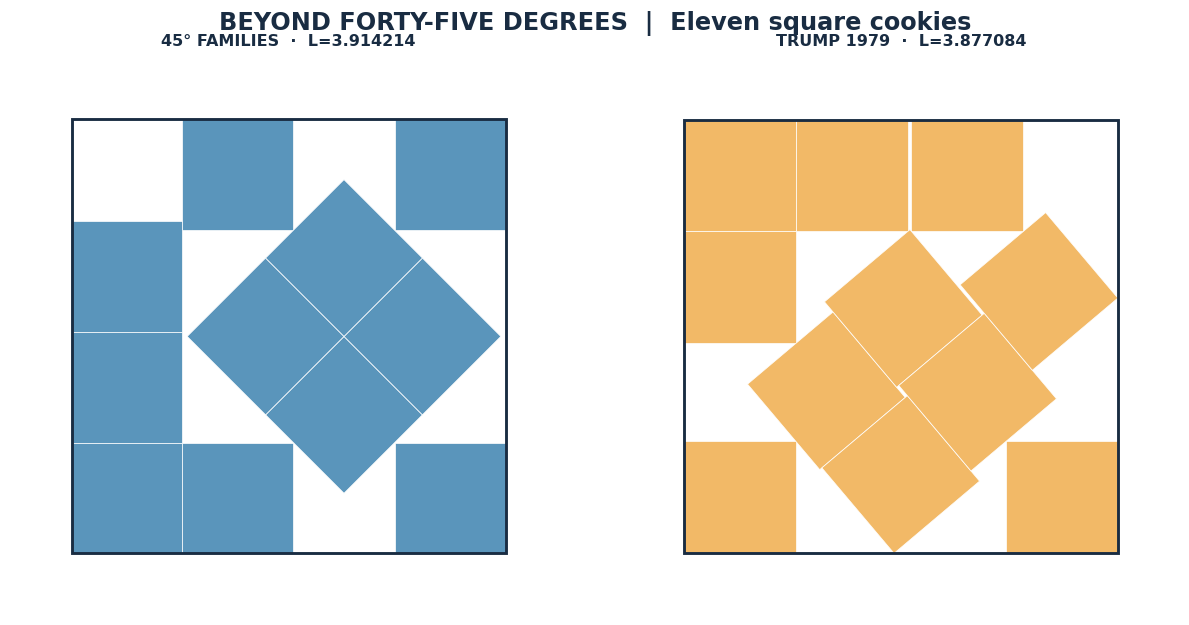

Rotation angle: 40.181937 degrees
V6 reference: 23.205993706
New local candidate: 23.112348897
Verified improvement: 0.093644809


In [18]:
# 18 — Walter Trump's (1979) eleven-square construction, from published formulas
# Provenance: Squares Project's reconstruction of the classic Trump / Ellsworth pose.
from scipy.optimize import brentq


def trump_eleven():
    """A numerical reproduction of Trump's published 11-unit-square packing.

    The polynomial/formulas are mathematical data, not a Kaggle competitor submission.
    Original discovery: Walter Trump (1979); algebraic reconstruction: Squares Project.
    """
    poly=[5,-10,-2,14,12,-6,2,2,-1]  # u = tan(angle/2)
    u=brentq(lambda t:np.polyval(poly,t), .36,.37,xtol=1e-15)
    co=(1-u*u)/(1+u*u)
    si=2*u/(1+u*u)
    theta=np.arctan2(si,co)
    S=(6*u+4)/(1+2*u-u*u)
    r1=1-(S-3)*co
    u1=((1+r1)*co-1)/si
    v1=co-si
    v2=(S-1)/si-r1-(3+u1)*co/si
    x0=1+2/co-(S-2)*si/co

    def axis_aligned(x,y):
        return np.array([[x,y],[x+1,y],[x+1,y+1],[x,y+1]],float)
    def tilted(x,y):
        pts=np.array([[x,y-r1],[x+1,y-r1],[x+1,y+1-r1],[x,y+1-r1]])
        rot=np.array([[co,-si],[si,co]])
        return pts@rot.T+[1,1]
    poly_verts=[axis_aligned(0,0),axis_aligned(S-1,0),
                axis_aligned(x0,S-1),axis_aligned(0,S-1),
                axis_aligned(1,S-1),axis_aligned(0,S-2),
                tilted(0,0),tilted(u1,-1),tilted(1,v1),
                tilted(u1+1,v1-1),tilted(u1+2,-v2)]
    result=[]
    for poly in poly_verts:
        edge=poly[1]-poly[0]
        result.append([*poly.mean(axis=0),np.arctan2(edge[1],edge[0])])
    return np.asarray(result),S

trump_pack,trump_L=trump_eleven()
trump_pack[:,:2]*=SAFETY_EXPANSION
assert len(trump_pack)==11
assert collision_audit(trump_pack)[0]==0
assert abs(side_length(trump_pack)-3.87708359)<1e-6

before11=submission.loc[submission.n.eq(11),['x','y','angle']].to_numpy()
if side_length(trump_pack) < side_length(before11)-1e-8:
    rows=submission.index[submission.n.eq(11)]
    ids=submission.loc[rows,'square_id'].to_numpy(dtype=int)
    submission.loc[rows,['x','y','angle']]=trump_pack[ids]
    if 11 not in changed:changed.append(11)
    method_by_n[11]='Trump 1979 / 40.18 degrees'
after=metrics(submission)

fig,axes=plt.subplots(1,2,figsize=(10.8,5.5))
draw_pack(axes[0],before11,f'45° FAMILIES  ·  L={side_length(before11):.6f}',BLUE)
draw_pack(axes[1],trump_pack,f'TRUMP 1979  ·  L={side_length(trump_pack):.6f}',GOLD)
fig.suptitle('BEYOND FORTY-FIVE DEGREES  |  Eleven square cookies',fontsize=15,weight='bold')
plt.tight_layout();plt.show()
print('Rotation angle:',round(float(np.degrees(trump_pack[6,2])),6),'degrees')
print('V6 reference:',f'{v6_metrics.score.sum():.9f}')
print('New local candidate:',f'{after.score.sum():.9f}')
print('Verified improvement:',f'{v6_metrics.score.sum()-after.score.sum():.9f}')
assert after.score.sum()<v6_metrics.score.sum()


**Finding 18.** The best rotation angle need not be 45° — sometimes it is close to 40.18°. I reconstructed the historical layout from published equations and checked it numerically.

<a id="e19"></a>
## 19 · Before / after: watch the courtyard appear

**Question.** Is the improvement visually explainable? I compare the old grid and the new, automatically selected layouts. Some panels use a diagonal band, others a central rotated block and corner staircases.

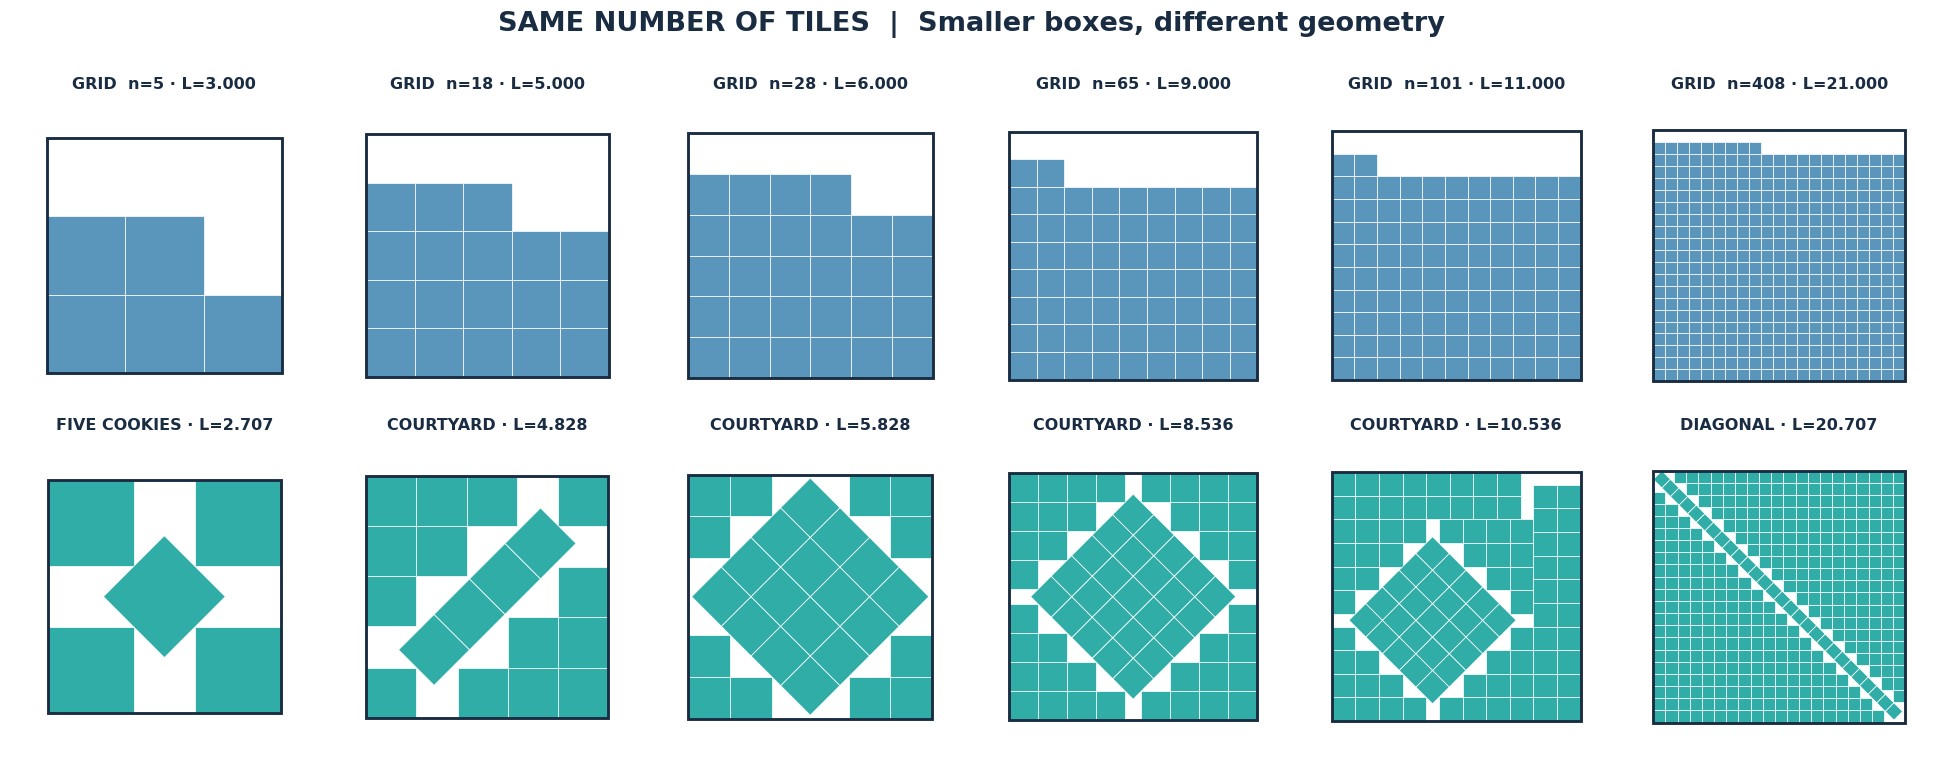

In [19]:
chosen = [5, 18, 28, 65, 101, 408]
fig, axes = plt.subplots(2, 6, figsize=(17, 6.7))
for col,n in enumerate(chosen):
    old = raw.loc[raw.n.eq(n), ["x","y","angle"]].to_numpy()
    new = submission.loc[submission.n.eq(n), ["x","y","angle"]].to_numpy()
    draw_pack(axes[0,col], old, f"GRID  n={n} · L={side_length(old):.3f}", BLUE)
    draw_pack(axes[1,col], new, f"{method_by_n.get(n,'grid').upper()} · L={side_length(new):.3f}", TEAL)
fig.suptitle("SAME NUMBER OF TILES  |  Smaller boxes, different geometry",
             fontsize=17, weight="bold", y=1.01)
plt.tight_layout(); plt.show()

**Finding 19.** There are now *two* different ways to break the grid: **diagonal seams** and **rotated courtyards**. The tournament automatically selects which is more compact for each `n` rather than assuming one trick wins everywhere.

<a id="e20"></a>
## 20 · Where did the extra score go?

**Question.** How many tasks improved? How much improvement does each construction contribute? This analysis uses the actual coordinates of the generated layouts, not hypothetical score estimates.

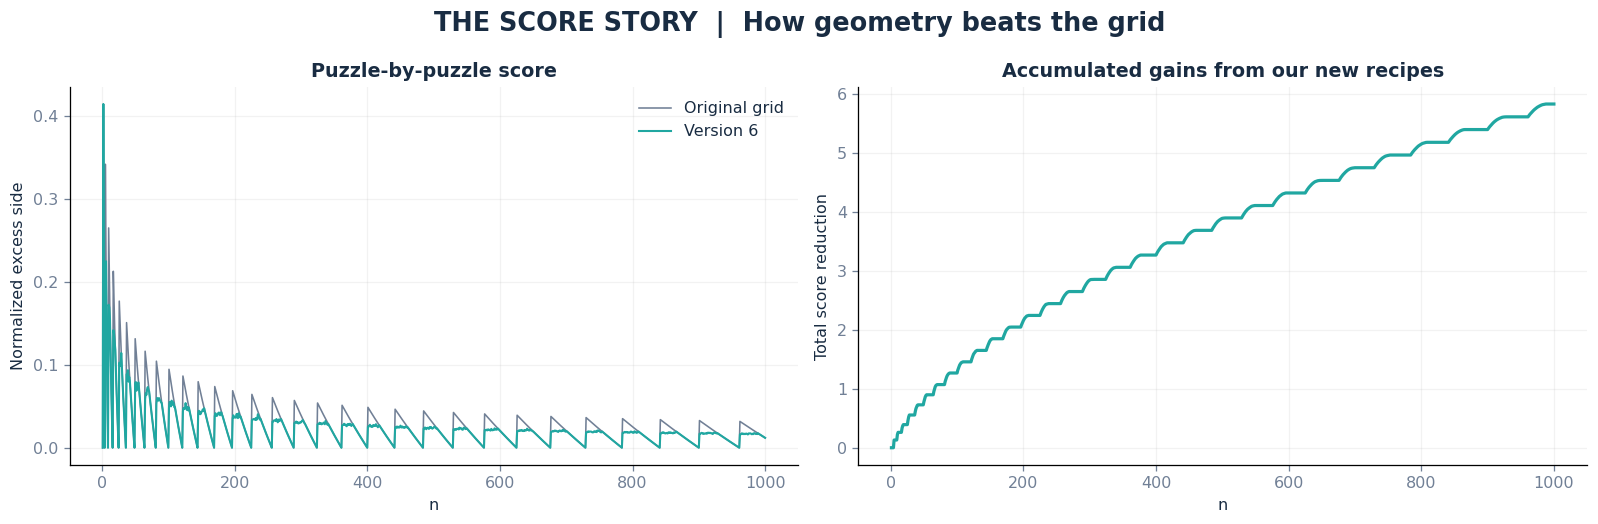

Score trajectory:
  Grid baseline: 28.937669917
  Published V1:  25.664479312
  New V7 local: 23.112348897
  Gain over V1: 2.552130415

Most improved puzzle sizes:


,grid,ours,gain,density_after
n,,,,
5,0.34164,0.21065,0.13099,0.68227
10,0.26491,0.17229,0.09262,0.72766
26,0.17670,0.10243,0.07427,0.82280
17,0.21268,0.14164,0.07104,0.76726
37,0.15079,0.08854,0.06225,0.84394
65,0.11631,0.05870,0.05761,0.89218
27,0.15470,0.09833,0.05637,0.82896
50,0.13137,0.07782,0.05355,0.86081
82,0.10432,0.05302,0.05129,0.90183


In [20]:
result = pd.DataFrame(index=baseline.index)
result["grid"] = baseline.score
result["ours"] = after.score
result["gain"] = result.grid - result.ours
result["density_before"] = baseline.density
result["density_after"] = after.density

v1_score = 25.664479312
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].plot(result.index, result.grid, label="Original grid", color=MUTED, lw=1)
axes[0].plot(result.index, result.ours, label="Version 6", color=TEAL, lw=1.3)
axes[0].legend(frameon=False)
axes[0].set(title="Puzzle-by-puzzle score", xlabel="n", ylabel="Normalized excess side")
axes[0].grid(alpha=.16)
axes[1].plot(result.index, result.gain.cumsum(), color=TEAL, lw=2)
axes[1].set(title="Accumulated gains from our new recipes", xlabel="n", ylabel="Total score reduction")
axes[1].grid(alpha=.16)
fig.suptitle("THE SCORE STORY  |  How geometry beats the grid", fontsize=16, weight="bold")
plt.tight_layout(); plt.show()

print("Score trajectory:")
print(f"  Grid baseline: {baseline.score.sum():.9f}")
print(f"  Published V1:  {v1_score:.9f}")
print(f"  New V7 local: {after.score.sum():.9f}")
print(f"  Gain over V1: {v1_score-after.score.sum():.9f}")
print("\nMost improved puzzle sizes:")
display(result.nlargest(12,"gain")[["grid","ours","gain","density_after"]].round(5))

**Finding 20.** A library of *small, explainable constructions* can beat a single clever trick. The cumulative-gain curve also shows which puzzle sizes are responsible for most of the improvement — a useful starting point for later optimization.

<a id="e21"></a>
## 21 · The geometry referee: numerical collision audit

**Question.** Does every improved arrangement preserve the submission schema and avoid interior overlap? I check every changed puzzle with the separating axis theorem. 

In [21]:
assert submission.shape == raw.shape
assert submission.id.equals(raw.id)
assert submission.n.equals(raw.n)
assert submission.square_id.equals(raw.square_id)
assert np.isfinite(submission[["x","y","angle"]].to_numpy()).all()
assert set(changed) == set(result.index[result.gain>1e-7]), "Unexpected score change"

checked_pairs = 0
for n in changed:
    p = submission.loc[submission.n.eq(n),["x","y","angle"]].to_numpy()
    assert len(p) == n
    conflicts, count = collision_audit(p, tol=1e-9)
    assert conflicts == 0, f"Overlap at n={n}: {conflicts} collisions"
    checked_pairs += count
print(f"✓ {len(changed)} changed puzzles passed numerical collision checks")
print(f"✓ {checked_pairs:,} nearby square pairs tested")
print(f"✓ {len(submission):,} output rows, IDs and puzzle indexes preserved")
print(f"✓ All puzzles have L no larger than their starting grid")
print(f"RECALCULATED LOCAL SCORE = {after.score.sum():.9f}  (lower is better)")

✓ 428 changed puzzles passed numerical collision checks
✓ 779,038 nearby square pairs tested
✓ 500,500 output rows, IDs and puzzle indexes preserved
✓ All puzzles have L no larger than their starting grid
RECALCULATED LOCAL SCORE = 23.112348897  (lower is better)


**Finding 21.** Independent validation is essential: a one-pixel-looking overlap can invalidate a puzzle. I audit the constructed coordinates after adding a tiny safety margin.

<a id="e22"></a>
## 22 · 🔪 Region Cropping — Win

**Question.** Could a useful packing be hiding *inside* a larger one?

The previous experiments kept the first `n` squares from a construction. That is convenient, but sometimes the densest `n` squares form a different region. I tried sliding an imaginary rectangular window across every V7 packing and keeping the squares fully inside it.

I started with the **1,000 packings generated earlier in this notebook**. Each candidate is a subset of an already valid packing; no squares need to be moved or rotated. The algorithm measures the actual container again after each crop.

This experiment is related to the idea of reusing local packing structures in [Kirill Tymchishin's Square Packing Lab](https://www.kaggle.com/code/kirilltym/square-packing-lab-cpu-cuda-mps) and [Chris Deotte's FTMC + MILP Refill](https://www.kaggle.com/code/cdeotte/squares-in-squares-ftmc-milp-refill-22-311). My test here is deliberately simpler: **crop the geometry I already constructed, then compare the side lengths**.

In [22]:
# Experiment 22 — Geometric Region Cropping. All source squares come from this notebook's V7 stage.
v9_reference = metrics(submission)
v9_source_packs = {int(n): p[['x','y','angle']].to_numpy().copy()
                   for n,p in submission.groupby('n',sort=True)}
v9_initial_L = np.r_[np.inf,v9_reference.L.to_numpy(dtype=float)]
v9_crop_L = v9_initial_L.copy()
v9_crop_packs, v9_crop_sources = {}, {}
v9_windows_tested = 0

for source_n, full_pack in v9_source_packs.items():
    if source_n < 15:
        continue
    half = .5*(np.abs(np.cos(full_pack[:,2]))+np.abs(np.sin(full_pack[:,2])))
    x_low = full_pack[:,0]-half; x_high = full_pack[:,0]+half
    y_low = full_pack[:,1]-half; y_high = full_pack[:,1]+half
    remove_budget = min(source_n-1, max(10, round(6*np.sqrt(source_n))))
    def boundary_choices(values, first):
        ordered = np.sort(values)
        return np.unique(ordered[:remove_budget+1] if first else ordered[-remove_budget-1:])
    x_left = boundary_choices(x_low, True)
    x_right = boundary_choices(x_high, False)
    y_bottom = boundary_choices(y_low, True)
    y_top = boundary_choices(y_high, False)

    if len(x_left)*len(x_right)*len(y_bottom)*len(y_top)>60000:
        # A bounded fallback for unusually irregular source packings.
        remove_budget = min(remove_budget,12)
        x_left = boundary_choices(x_low, True);x_right = boundary_choices(x_high, False)
        y_bottom = boundary_choices(y_low, True);y_top = boundary_choices(y_high, False)

    lowest_n=max(1,source_n-remove_budget)
    for left in x_left:
        xmask_left=(x_low>=left-1e-8)
        for right in x_right:
            width=right-left
            if width>=np.max(v9_crop_L[lowest_n:source_n+1])-1e-7:
                continue
            xmask=xmask_left&(x_high<=right+1e-8)
            if int(xmask.sum())<lowest_n:
                continue
            for bottom in y_bottom:
                mask_bottom=xmask&(y_low>=bottom-1e-8)
                if int(mask_bottom.sum())<lowest_n:
                    continue
                for top in y_top:
                    proposed_L=max(width,top-bottom)
                    if proposed_L>=np.max(v9_crop_L[lowest_n:source_n+1])-1e-7:
                        continue
                    mask=mask_bottom&(y_high<=top+1e-8)
                    capacity=int(mask.sum())
                    v9_windows_tested+=1
                    if capacity<lowest_n:
                        continue
                    options=np.flatnonzero(v9_crop_L[lowest_n:capacity+1]>proposed_L+1e-7)+lowest_n
                    if len(options)==0:
                        continue
                    region=full_pack[mask].copy()
                    for n in options:
                        trimmed=region[:n].copy()
                        actual_L=side_length(trimmed)
                        if actual_L < v9_crop_L[n]-1e-7:
                            v9_crop_L[n]=actual_L
                            v9_crop_packs[int(n)]=trimmed
                            v9_crop_sources[int(n)]=source_n

# Replace only complete puzzle packings. Never combine individual tiles from different solutions.
for n, candidate in sorted(v9_crop_packs.items()):
    assert len(candidate)==n and collision_audit(candidate)[0]==0
    rows=submission.index[submission.n.eq(n)]
    ids=submission.loc[rows,'square_id'].to_numpy(dtype=int)
    submission.loc[rows,['x','y','angle']]=candidate[ids]
v9_crop_metrics=metrics(submission)
v9_crop_gain=float(v9_reference.score.sum()-v9_crop_metrics.score.sum())
print('Geometric windows examined:',f'{v9_windows_tested:,}')
print('Improved puzzles:',len(v9_crop_packs))
print(f'Before: {v9_reference.score.sum():.9f}')
print(f'After region cropping: {v9_crop_metrics.score.sum():.9f}')
print(f'Win: -{v9_crop_gain:.9f} score')
assert v9_crop_gain>0

Geometric windows examined: 2,257,996
Improved puzzles: 29
Before: 23.112348897
After region cropping: 23.077933876
Win: -0.034415020 score


**Finding 22 — Win.** Cropping improved **29 puzzles** and reduced the local total from **23.112349 to 23.077934** (gain **0.034415**).

The improvements aren't all dramatic. Some windows save only a tiny strip along one edge. Across 1,000 puzzles, those small reductions add up. For `n = 235`, for example, I found a tighter region inside the packing originally built for `n = 267`.

The code tries a bounded set of windows near the packing boundaries. It doesn't prove that these are the best possible crops.

<a id="e23"></a>
## 23 · 🧲 Contact Reclosure with Linear Programming — Win

**Question.** After cropping, can I move the squares closer together without changing their angles?

I keep every rotation fixed and look at nearby square pairs. For each pair I select a separating axis from the current arrangement. That gives a collection of *linear* constraints on the centers, together with the four container walls. Then `scipy.optimize.linprog` tries to shorten the side length.

The separating-axis / fixed-angle repair idea also appears in [Kirill Tymchishin's Square Packing Lab](https://www.kaggle.com/code/kirilltym/square-packing-lab-cpu-cuda-mps). I implemented a bounded LP directly against the V7 and cropped coordinates, then rejected any candidate that failed the collision check.

One result is especially fun: **`n = 19`** approaches the classical side length `3 + 4√2 / 3 ≈ 4.885618`, discussed in [Erich Friedman's survey](https://erich-friedman.github.io/papers/squares/squares.html) in connection with Cottingham and Wainwright's arrangements.

In [23]:
# Experiment 23 — Fixed-angle contact reclosure, with SAT constraints and a linear program.
from scipy.optimize import linprog
from scipy import sparse

def contact_reclosure(pack, trust=.30, rounds=3):
    pack=np.asarray(pack,dtype=float).copy()
    n=len(pack)
    angle=pack[:,2]
    cosine,sine=np.cos(angle),np.sin(angle)
    half=(np.abs(cosine)+np.abs(sine))*.5
    pack[:,:2]-=np.min(pack[:,:2]-half[:,None],axis=0)
    best_side=side_length(pack)

    for iteration in range(rounds):
        centers=pack[:,:2]
        dim=2*n+1
        rid,cid,coeff,rhs=[],[],[],[]
        def restriction(cols,values,bound):
            row=len(rhs)
            rid.extend([row]*len(cols))
            cid.extend(cols)
            coeff.extend(values)
            rhs.append(bound)

        # Container walls (the container starts at x=y=0).
        for i in range(n):
            restriction([2*i],[-1],-half[i]-1e-9)
            restriction([2*i+1],[-1],-half[i]-1e-9)
            restriction([2*i,dim-1],[1,-1],-half[i]-1e-9)
            restriction([2*i+1,dim-1],[1,-1],-half[i]-1e-9)

        # Reuse a currently valid separating axis for each nearby pair.
        # The chosen axes stay fixed inside one linear programming step.
        nearby=cKDTree(centers).query_pairs(r=2.75+2*trust,output_type='ndarray')
        for i,j in nearby:
            delta=centers[j]-centers[i]
            axes=np.array([[cosine[i],sine[i]],[-sine[i],cosine[i]],
                           [cosine[j],sine[j]],[-sine[j],cosine[j]]])
            support=.5*(np.abs(axes[:,0]*cosine[i]+axes[:,1]*sine[i])
                      +np.abs(-axes[:,0]*sine[i]+axes[:,1]*cosine[i])
                      +np.abs(axes[:,0]*cosine[j]+axes[:,1]*sine[j])
                      +np.abs(-axes[:,0]*sine[j]+axes[:,1]*cosine[j]))
            projected=axes@delta
            clearance=np.abs(projected)-support
            k=int(np.argmax(clearance))
            if clearance[k]<-1e-7:
                return None  # Input arrangement is already infeasible.
            axis=axes[k]*(1 if projected[k]>=0 else -1)
            restriction([2*i,2*i+1,2*j,2*j+1],
                        [axis[0],axis[1],-axis[0],-axis[1]],
                        -support[k]-1e-9)

        A=sparse.coo_matrix((coeff,(rid,cid)),shape=(len(rhs),dim)).tocsr()
        bounds=[]
        for i in range(n):
            bounds.append((centers[i,0]-trust,centers[i,0]+trust))
            bounds.append((centers[i,1]-trust,centers[i,1]+trust))
        bounds.append((max(np.sqrt(n),best_side-1),best_side+1))
        objective=np.zeros(dim);objective[-1]=1
        solution=linprog(objective,A_ub=A,b_ub=np.array(rhs),bounds=bounds,
                         method='highs',options={'time_limit':60})
        if not solution.success:
            break
        candidate=pack.copy()
        candidate[:,:2]=solution.x[:2*n].reshape(n,2)
        next_side=side_length(candidate)
        if collision_audit(candidate,tol=5e-9)[0]:
            break
        pack=candidate
        if next_side >= best_side-1e-8:
            break
        best_side=next_side
    return pack

v9_lp_ref=v9_crop_metrics.copy()
v9_lp_wins={}
for n in sorted(set(v9_crop_packs)|{19}):
    before_pack=submission.loc[submission.n.eq(n),['x','y','angle']].to_numpy()
    candidate=contact_reclosure(before_pack)
    if candidate is None:
        continue
    if side_length(candidate)>=side_length(before_pack)-1e-5:
        continue
    if collision_audit(candidate)[0]:
        continue
    rows=submission.index[submission.n.eq(n)]
    ids=submission.loc[rows,'square_id'].to_numpy(dtype=int)
    submission.loc[rows,['x','y','angle']]=candidate[ids]
    v9_lp_wins[int(n)]=(side_length(before_pack),side_length(candidate))

v9_after=metrics(submission)
v9_lp_gain=float(v9_lp_ref.score.sum()-v9_after.score.sum())
print('Puzzles with additional LP gains:',list(v9_lp_wins))
print('Change in score:',round(v9_lp_gain,9))
print('V9 local score:',round(float(v9_after.score.sum()),9))
assert v9_after.score.sum()<v9_reference.score.sum()

Puzzles with additional LP gains: [19, 206, 546, 696]
Change in score: 0.008522529
V9 local score: 23.069411347


**Finding 23 — Win.** The LP found four meaningful improvements: `n = 19`, `206`, `546`, and `696`. It lowered the score by another **0.008523** on top of region cropping.

For `n = 19`, the enclosing side fell from **4.914214 to 4.885618**. This is a numerical recovery of a previously published geometric result, not a new mathematical optimum. The real lesson for me is that *the same angles can produce a smaller box once the contacts are rearranged*.

The search is intentionally bounded: fixed angles, nearby-pair constraints and a short LP sequence. It isn't a full square-packing optimizer.

<a id="e24"></a>
## 24 · 🎯 Rotate the Core a Little? — No Effect

I also tested a smaller angle experiment. On four V7 puzzles (`n = 26, 65, 101, 235`), I nudged the existing 45° core by **±0.04** and **±0.08 radians**, then tried to re-close the contacts with the LP.

These four examples are already tightly constrained. In this bounded test, none of the perturbed packings survived the geometric checks and improved the container. I kept the original constructions.

A failed experiment is still useful: it tells me that a core rotation needs more than a tiny local nudge.

In [24]:
# Experiment 24 — Control: modest rotations of the tilted group.
# A bounded test, not a claim that every possible angle has been explored.
angle_control=[]
for n in [26,65,101,235]:
    reference=v9_source_packs[n]
    L0=side_length(reference)
    best=L0
    valid_trials=0
    for delta in [-.08,-.04,.04,.08]:
        proposal=reference.copy()
        core=np.isclose(proposal[:,2],np.pi/4,atol=1e-5)
        if not core.any():
            continue
        origin=proposal[core,:2].mean(axis=0)
        cc,ss=np.cos(delta),np.sin(delta)
        rotation=np.array([[cc,-ss],[ss,cc]])
        proposal[core,:2]=(proposal[core,:2]-origin)@rotation.T+origin
        proposal[core,2]+=delta
        settled=contact_reclosure(proposal,trust=.30,rounds=2)
        if settled is None or collision_audit(settled)[0]:
            continue
        valid_trials+=1
        best=min(best,side_length(settled))
    angle_control.append({'n':n,'base_L':L0,'best_L':best,
                          'score_gain':(L0-best)/np.sqrt(n),
                          'valid_trials':valid_trials})
control_table=pd.DataFrame(angle_control)
display(control_table.round(7))
print('Total gain across the four control puzzles:',round(control_table.score_gain.sum(),9))

,n,base_L,best_L,score_gain,valid_trials
0,26,5.621320,5.621320,0.0,0
1,65,8.535534,8.535534,0.0,0
2,101,10.535534,10.535534,0.0,0
3,235,15.949748,15.949748,0.0,0


Total gain across the four control puzzles: 0.0


<a id="e25"></a>
## 25 · 📈 Experiments & Results — Every Gain Counts

This is my favorite part: not just the final score, but **which puzzles changed and why**.

| Experiment | Before | After | Result |
|:--|--:|--:|:--|
| Region cropping | `23.112349` | `23.077934` | **Win · −0.034415** |
| Fixed-angle contact LP | `23.077934` | `23.069411` | **Win · −0.008523** |
| Small core-angle perturbations | `23.069411` | `23.069411` | **No effect** |

**Local V9 result: `23.069411`.** That's an improvement of approximately **0.042938** over the confirmed V7 score. The next plots use the actual generated layouts and the full 1,000-puzzle scoring curve.

Improved puzzle counts: 30
Top score gains:


,n,source,method,before_L,after_L,gain
18,19,NaN,contact LP,4.914214,4.885618,0.006560
202,203,263.0,crop,14.828427,14.778175,0.003527
205,206,267.0,crop + LP,14.949748,14.899495,0.003501
234,235,267.0,crop,15.949748,15.899495,0.003278
151,152,177.0,crop,12.899495,12.863961,0.002882
302,303,340.0,crop,17.985281,17.949748,0.002041
412,413,455.0,crop,20.899495,20.863961,0.001749
545,546,642.0,crop + LP,23.935029,23.899495,0.001521
802,803,919.0,crop,28.899495,28.859650,0.001406
373,374,455.0,crop,19.899495,19.874369,0.001299


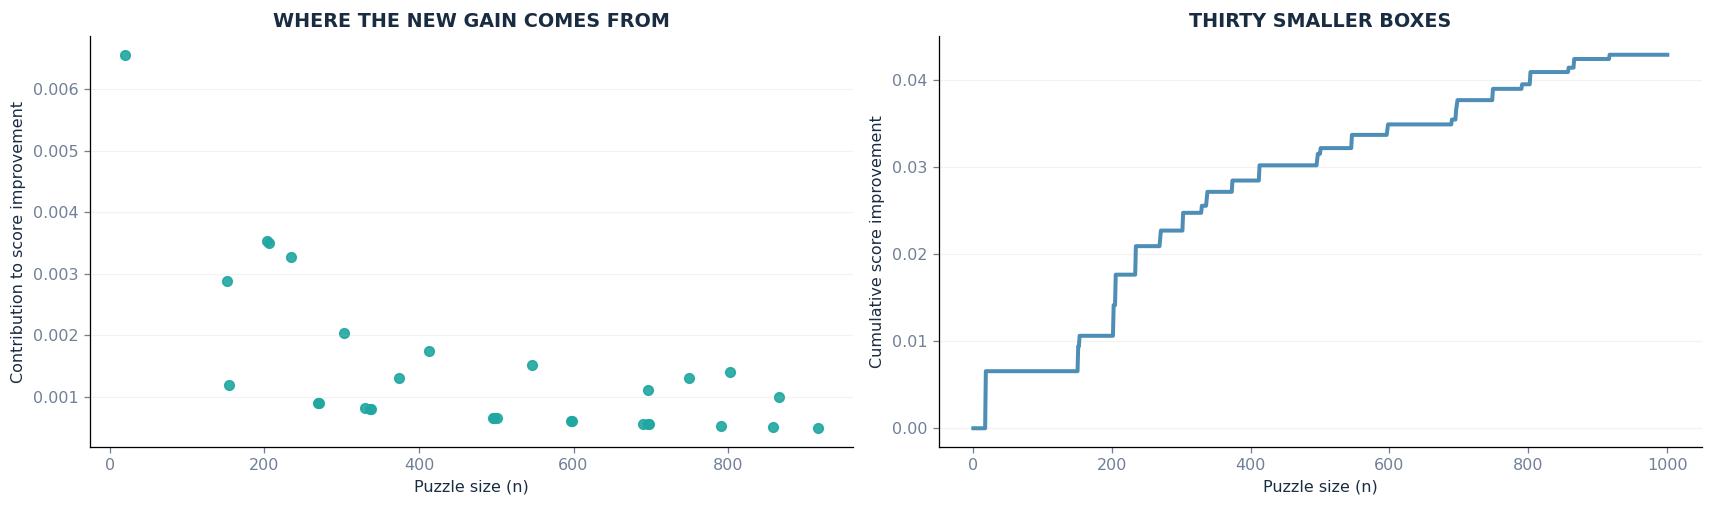

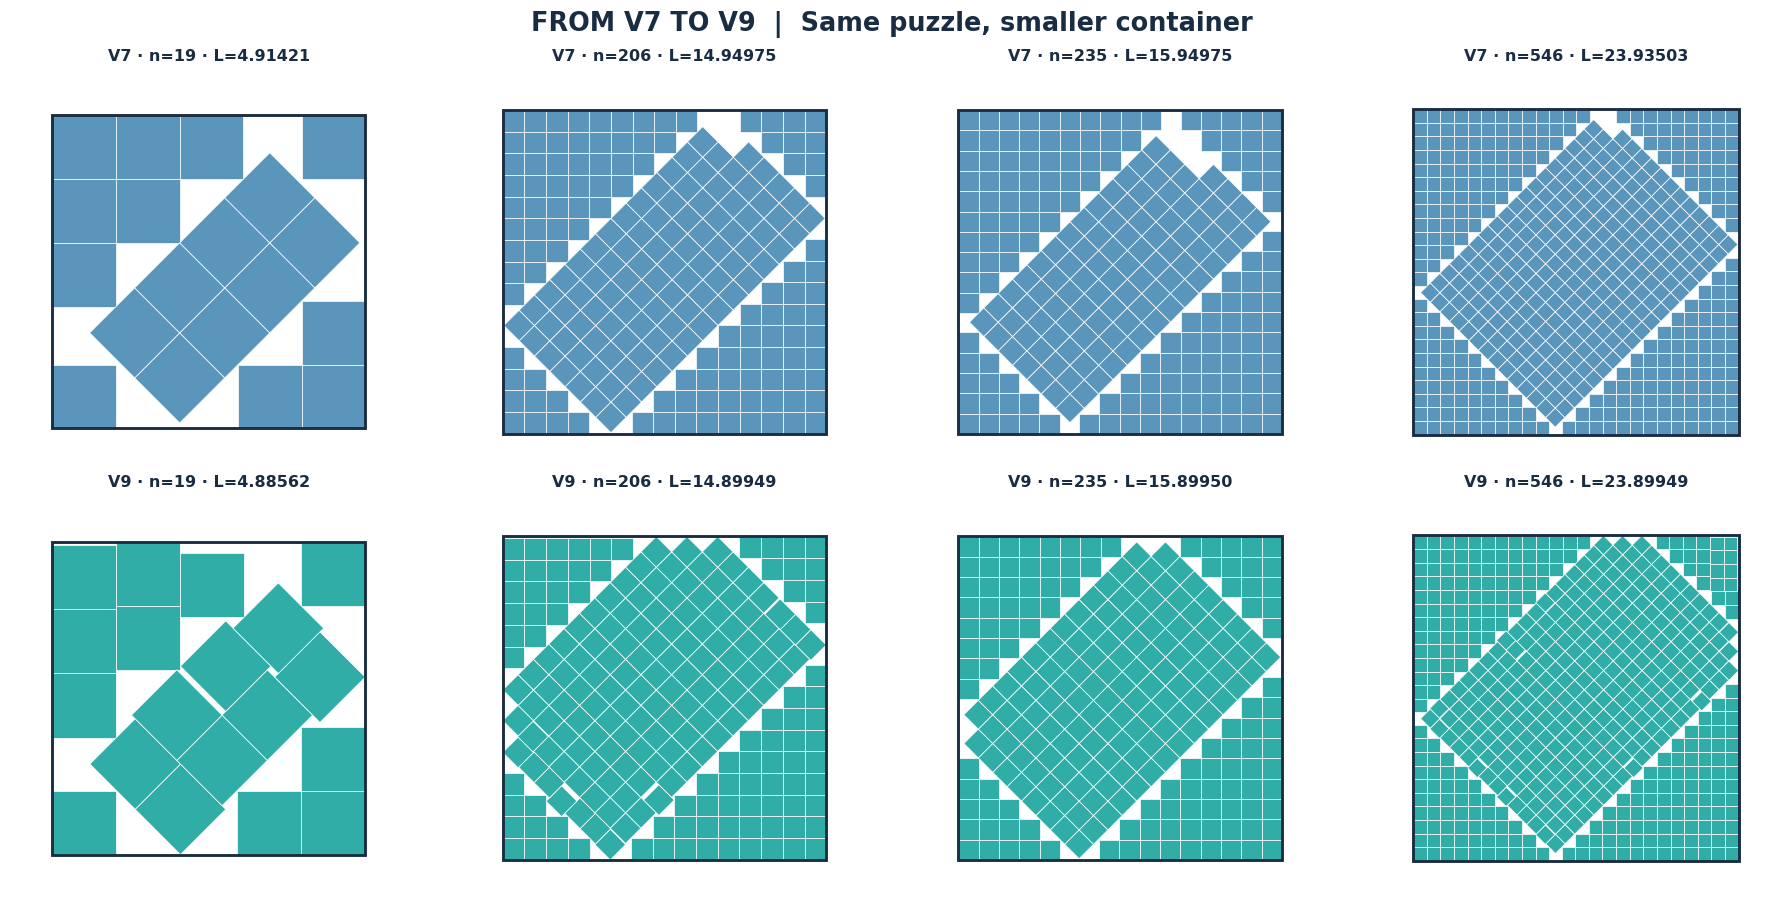

In [25]:
v9_changed = sorted(set(v9_crop_packs) | set(v9_lp_wins))
v9_ledger = pd.DataFrame({
    'n': np.arange(1,1001),
    'before_L': v9_reference.L.to_numpy(),
    'after_L': v9_after.L.to_numpy(),
    'before_score': v9_reference.score.to_numpy(),
    'after_score': v9_after.score.to_numpy(),
})
v9_ledger['gain']=v9_ledger.before_score-v9_ledger.after_score
v9_ledger['source'] = v9_ledger.n.map(v9_crop_sources)
v9_ledger['method']=v9_ledger.n.map(lambda n: 'crop + LP' if n in v9_lp_wins and n in v9_crop_packs
                                     else 'contact LP' if n in v9_lp_wins else
                                     'crop' if n in v9_crop_packs else 'unchanged')
print('Improved puzzle counts:',len(v9_changed))
print('Top score gains:')
display(v9_ledger.nlargest(12,'gain')[['n','source','method','before_L','after_L','gain']].round(7))

fig,axes=plt.subplots(1,2,figsize=(15,4.5))
positive=v9_ledger[v9_ledger.gain>1e-8]
axes[0].scatter(positive.n,positive.gain,c=TEAL,s=36,alpha=.9)
axes[0].set(xlabel='Puzzle size (n)',ylabel='Contribution to score improvement',
            title='WHERE THE NEW GAIN COMES FROM')
axes[0].grid(axis='y')
axes[1].plot(v9_ledger.n,v9_ledger.gain.cumsum(),c=BLUE,lw=2.5)
axes[1].set(xlabel='Puzzle size (n)',ylabel='Cumulative score improvement',
            title='THIRTY SMALLER BOXES')
axes[1].grid(axis='y')
plt.tight_layout();plt.show()

examples=[19,206,235,546]
fig,axes=plt.subplots(2,len(examples),figsize=(16,8))
for j,n in enumerate(examples):
    before=v9_source_packs[n]
    after_pack=submission.loc[submission.n.eq(n),['x','y','angle']].to_numpy()
    draw_pack(axes[0,j],before,f'V7 · n={n} · L={side_length(before):.5f}',BLUE)
    draw_pack(axes[1,j],after_pack,f'V9 · n={n} · L={side_length(after_pack):.5f}',TEAL)
fig.suptitle('FROM V7 TO V9  |  Same puzzle, smaller container',fontsize=16,weight='bold')
plt.tight_layout();plt.show()

<a id="e26"></a>
## 26 · 🛡️ Audit Before Export

The acceptance rule is simple: **the entire puzzle must improve, every tile must still exist, and no two interiors may overlap**.

I check all 30 changed puzzles with the same separating-axis collision routine used earlier. Then I export the CSV and recalculate the score **from the serialized coordinates**, not from a rounded number in the text.

In [26]:
assert submission.shape == raw.shape
assert submission.id.equals(raw.id)
assert submission.n.equals(raw.n)
assert submission.square_id.equals(raw.square_id)
assert np.isfinite(submission[['x','y','angle']].to_numpy()).all()
assert len(v9_changed)==30
assert (v9_after.L <= v9_reference.L+1e-7).all()
for n in v9_changed:
    pack=submission.loc[submission.n.eq(n),['x','y','angle']].to_numpy()
    assert len(pack)==n
    overlaps,nearby=collision_audit(pack,tol=1e-9)
    assert overlaps==0, f'n={n}: {overlaps} overlapping pairs'
print('Verified geometry for',len(v9_changed),'changed puzzles.')
print(f'V7 local score: {v9_reference.score.sum():.10f}')
print(f'V9 local score: {v9_after.score.sum():.10f}')
print(f'Gain:           {v9_reference.score.sum()-v9_after.score.sum():.10f}')

Verified geometry for 30 changed puzzles.
V7 local score: 23.1123488967
V9 local score: 23.0694113469
Gain:           0.0429375498


<a id="e27"></a>
## 27 · Save the V9 checkpoint

I keep the previous result in a separate file, then run the Version 10 experiments below. The final `submission.csv` is exported at the end of the notebook.


In [27]:
output_path = Path('/kaggle/working/submission_V9_checkpoint.csv')
submission.to_csv(output_path,index=False,float_format='%.16g')
reloaded=pd.read_csv(output_path,float_precision='round_trip')
assert len(reloaded)==500_500
assert reloaded.id.equals(submission.id)
serialized=metrics(reloaded)
for n in v9_changed:
    q=reloaded.loc[reloaded.n.eq(n),['x','y','angle']].to_numpy()
    assert collision_audit(q,tol=1e-9)[0]==0, f'Serialized puzzle {n} overlaps'
assert serialized.score.sum() <= v9_reference.score.sum()-0.04
print('Saved:',output_path)
print('Rows:',len(reloaded),'· improved puzzles:',len(v9_changed))
print(f'Serialized local score: {serialized.score.sum():.10f}')
print(f'Gain over V7: {v9_reference.score.sum()-serialized.score.sum():.10f}')
print(f'File size: {output_path.stat().st_size/1e6:.2f} MB')

Saved: /kaggle/working/submission_V9_checkpoint.csv
Rows: 500500 · improved puzzles: 30
Serialized local score: 23.0694113469
Gain over V7: 0.0429375498
File size: 19.43 MB


---
<a id="v9-checkpoint"></a>
## V9 checkpoint — where the previous version stopped

| Experiment | Result |
|:--|:--|
| **22 · Region cropping** | Smaller regions improved 29 puzzles. |
| **23 · Fixed-angle LP** | Contact reclosure added four improvements, including `n = 19`. |
| **24 · Core-angle nudges** | No effect in a bounded four-puzzle test. |
| **25–27 · Audit and export** | **23.0694113469** — confirmed on Kaggle as Version 9. |

The next experiments start from this checked V9 geometry. They don't load solutions or coordinates from other notebooks.

<a id="e28"></a>
## 28 · 🔧 Free-Angle Contact Refinement — Win

**Question.** The earlier LP moved only the centres. What happens if the angles can move too?

A square has three variables: `x`, `y`, and `angle`. I linearize the local separating-axis and wall constraints, solve a small linear program, and then check the **actual nonlinear geometry**. If the trial overlaps, I reject it. If it is valid but the container isn't smaller, I keep the previous packing.

This experiment is inspired by the contact-refinement ideas in [Kirill Tymchishin's Square Packing Lab](https://www.kaggle.com/code/kirilltym/square-packing-lab-cpu-cuda-mps) and [prvsiyan's *A Square Deal*](https://www.kaggle.com/code/prvsiyan/a-square-deal-research-to-verified-packings). The compact CPU implementation below is written for this notebook and starts only from the packings generated in Experiments 01–27. No external solution files are loaded.

I use fixed seeds and a short search schedule. This is a **local improvement method**, not a claim to have solved global square packing.

In [28]:
# Version 10 — fresh, bounded optimization on the notebook's own V9 layouts.
# The preceding cell names the public research that inspired this method.
# A compact, self-contained SAT-linearized sequential LP.
# Implemented for this experiment; mathematical approach credited in the preceding Markdown.
import math
import numpy as np
from scipy.optimize import linprog
from scipy.sparse import coo_matrix
from scipy.spatial import cKDTree

def extent(theta):
    return .5*(np.abs(np.cos(theta))+np.abs(np.sin(theta)))

def side(p):
    h=extent(p[:,2]);return float(max(np.max(p[:,0]+h)-np.min(p[:,0]-h),
                     np.max(p[:,1]+h)-np.min(p[:,1]-h)))

def valid_and_repair(p, clearance=3e-10):
    p=p.copy(); h=extent(p[:,2]);p[:,0]-=np.min(p[:,0]-h);p[:,1]-=np.min(p[:,1]-h)
    pairs=cKDTree(p[:,:2]).query_pairs(1.6,output_type='ndarray')
    ratio=1.
    for i,j in pairs:
        d=p[j,:2]-p[i,:2];a,b=p[i,2],p[j,2];c=np.cos((a,b));s=np.sin((a,b))
        axes=((c[0],s[0]),(-s[0],c[0]),(c[1],s[1]),(-s[1],c[1]))
        support=(1+abs(math.cos(a-b))+abs(math.sin(a-b)))/2
        maxproj=max(abs(d[0]*vx+d[1]*vy) for vx,vy in axes)
        ratio=max(ratio,(support+clearance)/max(maxproj,1e-30))
    if ratio>1.004:return None
    p[:,:2]*=ratio
    return p

def contact_slp(seed_pack,random_seed=0,trust=.05,rounds=22,max_seconds=1.5):
    import time
    p=valid_and_repair(seed_pack)
    if p is None:return None,0
    n=len(p);rng=np.random.default_rng(random_seed);start=time.time();step=trust;accepted=0
    for iteration in range(rounds):
        if time.time()-start>max_seconds:break
        L=side(p);x,y,t=p.T;c=np.cos(t);s=np.sin(t);h=extent(t)
        N=3*n+1
        rows=[];cols=[];values=[];rhs=[]
        def con(ix,coef,r):
            row=len(rhs);rows.extend([row]*len(ix));cols.extend(ix);values.extend(coef);rhs.append(r)
        # Wall constraints with derivatives; angle kinks use both subgradients.
        for i in range(n):
            derivative=(-s[i]*np.sign(c[i])+c[i]*np.sign(s[i]))/2
            derivatives=[derivative] if min(abs(c[i]),abs(s[i]))>1e-8 else [-.5,.5]
            for dh in derivatives:
                con((3*i,3*i+2),(-1,dh),x[i]-h[i]-2e-10)
                con((3*i+1,3*i+2),(-1,dh),y[i]-h[i]-2e-10)
                con((3*i,3*i+2,3*n),(1,dh,-1),L-x[i]-h[i]-2e-10)
                con((3*i+1,3*i+2,3*n),(1,dh,-1),L-y[i]-h[i]-2e-10)
        pairs=cKDTree(p[:,:2]).query_pairs(1.9,output_type='ndarray')
        for i,j in pairs:
            d=p[j,:2]-p[i,:2];delta=t[i]-t[j]
            axes=((c[i],s[i],-s[i],c[i],True),(-s[i],c[i],-c[i],-s[i],True),
                  (c[j],s[j],-s[j],c[j],False),(-s[j],c[j],-c[j],-s[j],False))
            support=(1+abs(np.cos(delta))+abs(np.sin(delta)))/2
            proj=np.array([abs(d[0]*a[0]+d[1]*a[1]) for a in axes]);
            admissible=np.flatnonzero(proj>proj.max()-1e-9)
            axisid=int(rng.choice(admissible))
            ax,ay,px,py,belongs_i=axes[axisid]
            dot=d[0]*ax+d[1]*ay;sign=np.sign(dot) if abs(dot)>1e-12 else 1
            vx,vy=sign*ax,sign*ay
            angle_grad=sign*(d[0]*px+d[1]*py)
            derivative=(-np.sin(delta)*np.sign(np.cos(delta))+np.cos(delta)*np.sign(np.sin(delta)))/2
            slopes=[derivative] if min(abs(np.cos(delta)),abs(np.sin(delta)))>1e-8 else [-.5,.5]
            for slope in slopes:
                di=-slope+(angle_grad if belongs_i else 0.)
                dj=slope+(angle_grad if not belongs_i else 0.)
                con((3*i,3*i+1,3*j,3*j+1,3*i+2,3*j+2),
                    (vx,vy,-vx,-vy,-di,-dj),abs(dot)-support-3e-10)
        M=coo_matrix((values,(rows,cols)),shape=(len(rhs),N)).tocsr()
        goal=np.zeros(N);goal[-1]=1
        bounds=[(-step,step) if k%3!=2 else (-step*.4,step*.4) for k in range(3*n)]+[(-step,step)]
        fit=linprog(goal,A_ub=M,b_ub=np.asarray(rhs),bounds=bounds,method='highs',options={'time_limit':.3})
        if not fit.success:
            step*=.5
            if step<3e-7:break
            continue
        proposal=fit.x[:3*n].reshape(n,3)
        best=None;bestL=L
        for damping in (1.,.5,.25,.125,.0625,.03125):
            q=valid_and_repair(p+proposal*damping)
            if q is not None:
                w=side(q)
                if w<bestL-1e-9:bestL=w;best=q
        if best is None:
            step*=.5
            if step<3e-7:break
        else:
            p=best;accepted+=1;step=min(.075,step*1.25)
    return p,accepted

# Snapshot: every candidate must be compared with the actual V9 geometry.
v10_reference = metrics(submission)
v10_bank = {int(n): rows[['x','y','angle']].to_numpy(dtype=float).copy()
            for n, rows in submission.groupby('n',sort=True)}
v10_history = []

def v10_offer(n, candidate, method, seed_n):
    if candidate is None or len(candidate) != n:
        return False
    previous = side(v10_bank[n])
    proposed = side(candidate)
    if proposed >= previous - 2e-6:
        return False
    overlaps, _ = collision_audit(candidate, tol=1e-9)
    if overlaps:
        return False
    v10_bank[n] = candidate.copy()
    v10_history.append({'n': n, 'method': method, 'seed_n': seed_n,
                        'before_L': previous, 'after_L': proposed,
                        'gain': (previous-proposed)/np.sqrt(n)})
    print(f'WIN  n={n:3d}  {previous:.9f} → {proposed:.9f}  ({method})')
    return True

# A small, fixed schedule — chosen by testing on V9, not by reading a top CSV.
q, _ = contact_slp(v10_bank[37], random_seed=29, trust=.06, rounds=15, max_seconds=2.0)
v10_offer(37, q, 'free-angle SLP', 37)

# Two passes are useful for the fifty-four-square courtyard.
q = v10_bank[54].copy()
best_side = side(q)
for sweep in range(2):
    for rng_seed in (11,29,42,71,123,333):
        for radius in (.025,.06,.10):
            trial, _ = contact_slp(q if sweep else v10_bank[54],
                                   random_seed=rng_seed+5*sweep,
                                   trust=radius, rounds=15, max_seconds=2.0)
            if trial is not None and side(trial) < best_side - 1e-5:
                q, best_side = trial.copy(), side(trial)
v10_offer(54, q, 'free-angle SLP · two passes', 54)

for n, rng_seed, radius in [(87,29,.06), (107,123,.025), (123,11,.025)]:
    trial, _ = contact_slp(v10_bank[n], random_seed=rng_seed,
                           trust=radius, rounds=15, max_seconds=2.0)
    v10_offer(n, trial, 'free-angle SLP', n)

print('Free-angle stage gain:',round(sum(r['gain'] for r in v10_history),9))

WIN  n= 37  6.621320400 → 6.604015296  (free-angle SLP)
WIN  n= 54  7.914213632 → 7.866281838  (free-angle SLP · two passes)
WIN  n= 87  9.863961119 → 9.862831987  (free-angle SLP)
WIN  n=107  10.914213662 → 10.913274105  (free-angle SLP)
Free-angle stage gain: 0.009579518


<a id="e29"></a>
## 29 · 🧱 Border Transfer — Win

**Question.** If a packing gets shorter for `n` squares, can that gain help another puzzle?

I add an **L-shaped border**: a row of upright squares above the old box and a column on its right. The number of new tiles is determined by the actual side length, not by a guessed count. Every resulting packing gets checked again.

The classical border-extension idea appears in [Erich Friedman's survey](https://erich-friedman.github.io/papers/squares/squares.html), and related reuse experiments appear in [Kirill Tymchishin's work](https://www.kaggle.com/code/kirilltym/square-packing-lab-cpu-cuda-mps). Here the seed is **my improved `n = 37` or `n = 54` layout** from Experiment 28.

I also give the newly framed `n = 50` packing one more short contact-refinement pass. This produces an extra gain without changing the source of the squares.

In [29]:
def v10_add_border(pack):
    p = np.asarray(pack, dtype=float).copy()
    h = extent(p[:,2])
    p[:,0] -= np.min(p[:,0]-h)
    p[:,1] -= np.min(p[:,1]-h)
    old_L = side(p)
    k = math.floor(old_L + 1e-9)
    # k tiles above; k+1 tiles on the right, including the outer corner.
    strip = np.array([(i+.5,old_L+.5,0.) for i in range(k)] +
                     [(old_L+.5,j+.5,0.) for j in range(k+1)])
    q = np.vstack((p, strip))
    q[:,:2] *= 1 + 1e-9  # tiny numerical clearance for exact contacts
    return q

for src in (37,54,87,107,123):
    seed = v10_bank[src].copy()
    for border in range(1,10):
        extended = v10_add_border(seed)
        target_n = len(extended)
        if target_n > 1000:
            break
        v10_offer(target_n, extended, f'L-border · step {border}', src)
        if src in (37,54) and border == 1:
            tightened, _ = contact_slp(extended, random_seed=11, trust=.06,
                                       rounds=10, max_seconds=2.0)
            v10_offer(target_n, tightened, 'L-border + free-angle SLP', src)
        seed = extended

v10_changed = sorted({row['n'] for row in v10_history})
print('Improved puzzle sizes:',v10_changed)
print('Candidate wins:',len(v10_history),'· unique puzzles:',len(v10_changed))

WIN  n= 50  7.621320410 → 7.604015303  (L-border · step 1)
WIN  n= 50  7.604015303 → 7.601870285  (L-border + free-angle SLP)
WIN  n= 69  8.914213642 → 8.866281845  (L-border · step 1)
Improved puzzle sizes: [37, 50, 54, 69, 87, 107]
Candidate wins: 7 · unique puzzles: 6


<a id="e30"></a>
## 30 · 📈 Experiments & Results — The V10 Ledger

I compare the **full 1,000-puzzle score** before and after each new idea. The result isn't built from another participant's CSV: it starts from the V9 constructions in this notebook.

| Experiment | Starting score | What I tested | Outcome |
|:--|--:|:--|:--|
| V9 checkpoint | `23.069411` | Region cropping + fixed-angle LP | Starting point |
| Free-angle contact refinement | `23.069411` | Adjust centres and angles together | **Win** |
| L-border transfer + short refinement | After free-angle LP | Reuse the improved small packings | **Win** |

Six puzzle sizes change in the verified V10 candidate: **37, 50, 54, 69, 87, 107**. The figures below show the geometry and the score contributions rather than only the final number.

V9 Kaggle baseline:    23.0694113469
Version 10 candidate:  23.0513108553
Improvement:           0.0181004916


,n,before_L,after_L,gain
0,37,6.621320,6.604015,0.002845
1,50,7.621320,7.601870,0.002751
2,54,7.914214,7.866282,0.006523
3,69,8.914214,8.866282,0.005770
4,87,9.863961,9.862832,0.000121
5,107,10.914214,10.913274,0.000091


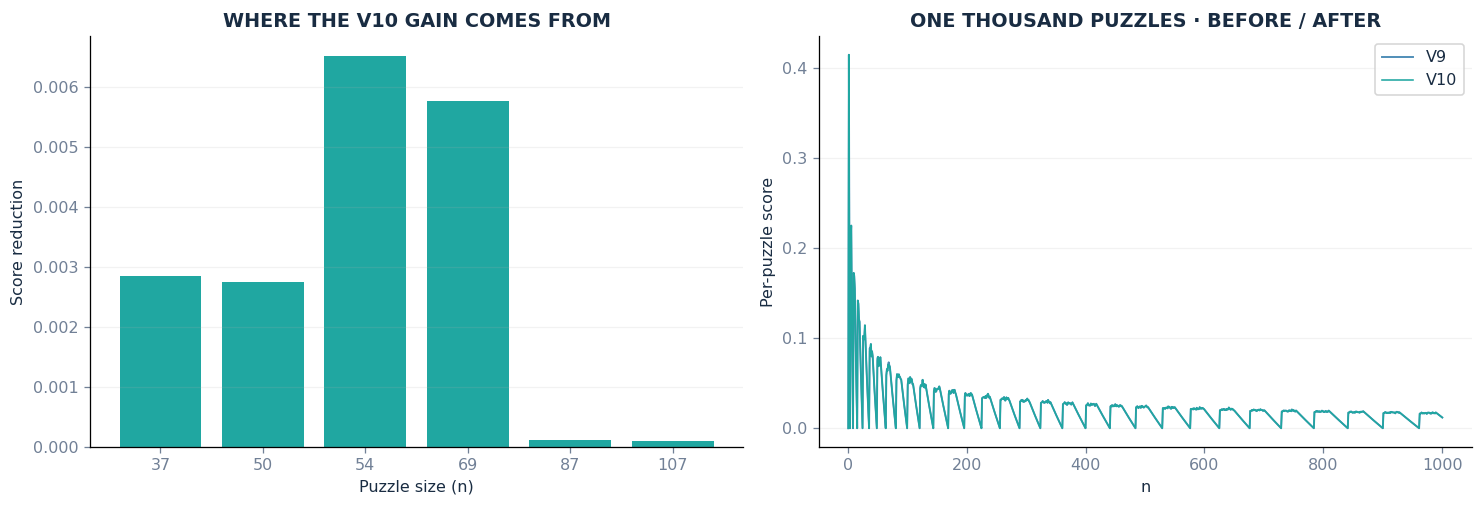

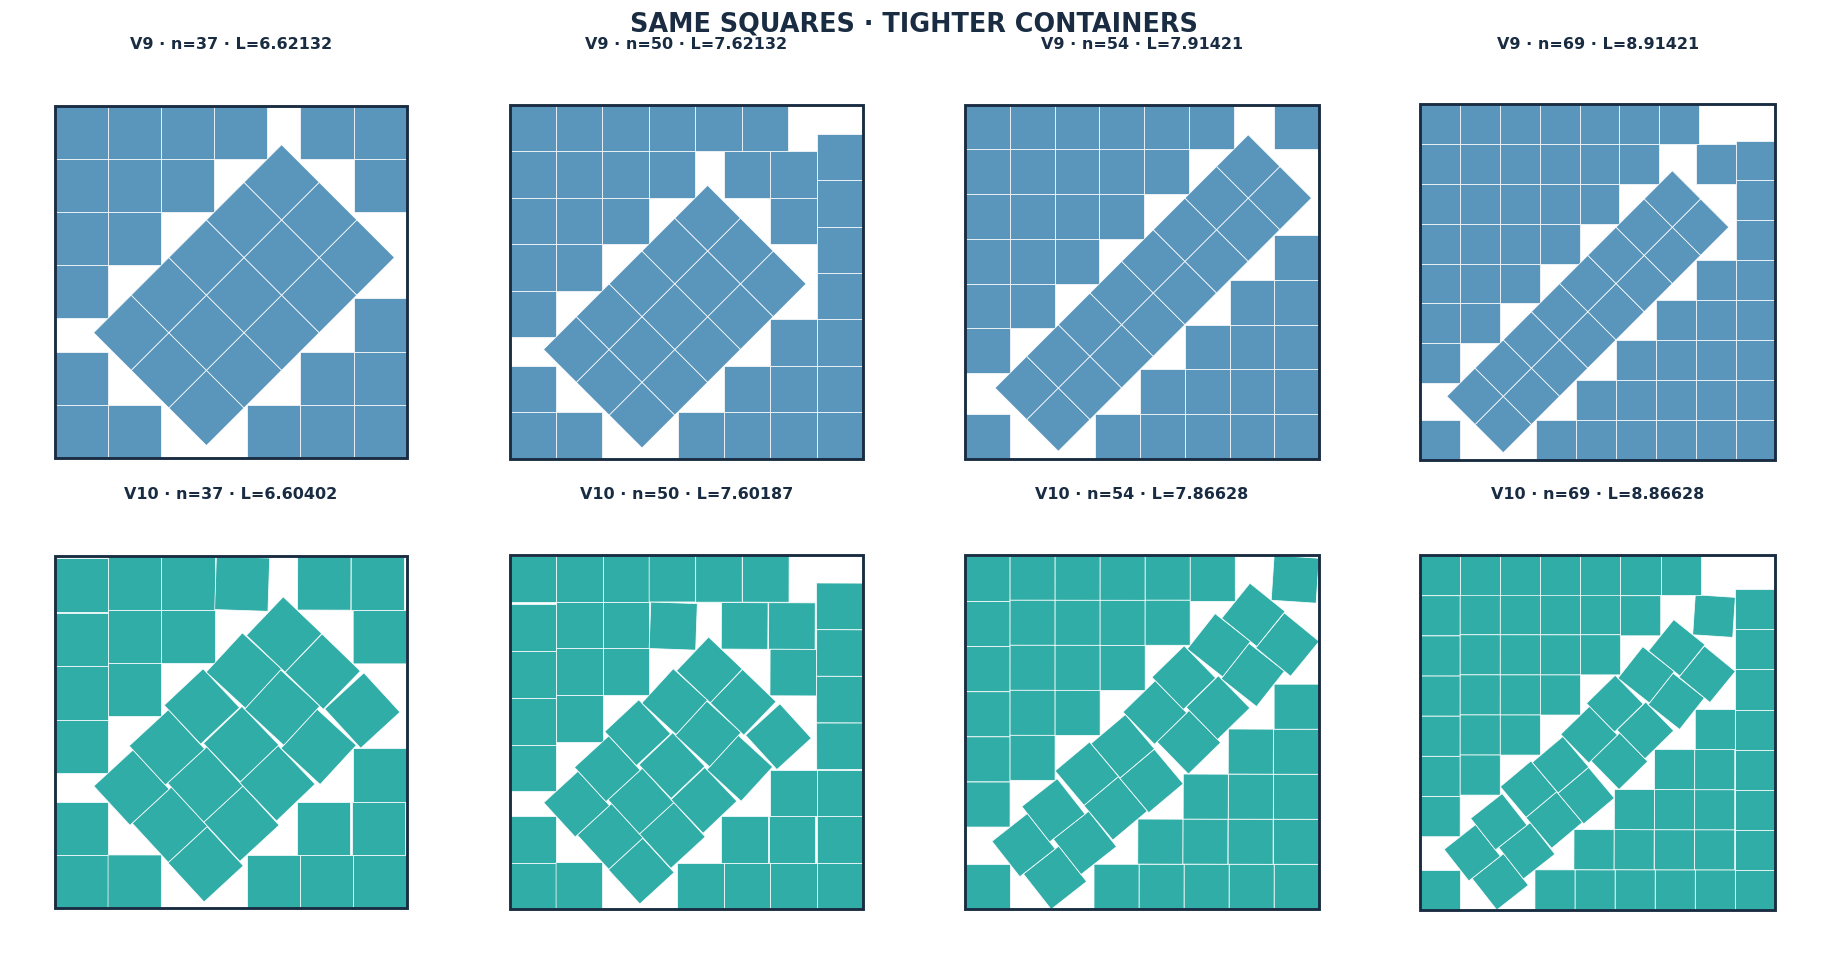

In [30]:
# Transfer complete accepted geometries into the competition submission table.
v10_submission = submission.copy()
for n in v10_changed:
    ix = v10_submission.index[v10_submission.n.eq(n)]
    ids = v10_submission.loc[ix,'square_id'].to_numpy(dtype=int)
    v10_submission.loc[ix,['x','y','angle']] = v10_bank[n][ids]

v10_after = metrics(v10_submission)
v10_score = float(v10_after.score.sum())
v10_gain = float(v10_reference.score.sum() - v10_score)
assert v10_score < v10_reference.score.sum() - .005

v10_ledger = pd.DataFrame({
    'n': v10_changed,
    'before_L': v10_reference.loc[v10_changed,'L'].to_numpy(),
    'after_L': v10_after.loc[v10_changed,'L'].to_numpy(),
})
v10_ledger['gain'] = ((v10_ledger.before_L-v10_ledger.after_L)
                     /np.sqrt(v10_ledger.n))
print(f'V9 Kaggle baseline:    {v10_reference.score.sum():.10f}')
print(f'Version 10 candidate:  {v10_score:.10f}')
print(f'Improvement:           {v10_gain:.10f}')
display(v10_ledger.round(8))

fig,axes=plt.subplots(1,2,figsize=(13,4.5))
axes[0].bar(v10_ledger.n.astype(str),v10_ledger.gain,color=TEAL)
axes[0].set(title='WHERE THE V10 GAIN COMES FROM',xlabel='Puzzle size (n)',ylabel='Score reduction')
axes[0].grid(axis='y')
axes[1].plot(v10_reference.index,v10_reference.score,c=BLUE,lw=1.2,label='V9')
axes[1].plot(v10_after.index,v10_after.score,c=TEAL,lw=1.0,label='V10')
axes[1].set(title='ONE THOUSAND PUZZLES · BEFORE / AFTER',xlabel='n',ylabel='Per-puzzle score')
axes[1].legend();axes[1].grid(axis='y')
plt.tight_layout();plt.show()

for n in (37,50,54,69):
    pass  # visual gallery below uses the same exact accepted arrays
fig,axs=plt.subplots(2,4,figsize=(16,8.5))
for j,n in enumerate((37,50,54,69)):
    original=submission.loc[submission.n.eq(n),['x','y','angle']].to_numpy()
    accepted=v10_bank[n]
    draw_pack(axs[0,j],original,f'V9 · n={n} · L={side_length(original):.5f}',BLUE)
    draw_pack(axs[1,j],accepted,f'V10 · n={n} · L={side_length(accepted):.5f}',TEAL)
fig.suptitle('SAME SQUARES · TIGHTER CONTAINERS',fontsize=16,weight='bold')
plt.tight_layout();plt.show()

<a id="e31"></a>
## 31 · 🛡️ Validate the New Geometry — Before Saving

Six complete packings have changed. I verify that the submission still has **500,500 rows**, each puzzle contains exactly its required number of squares, and the six modified layouts have no overlapping interiors.

The offline candidate was also evaluated with the public competition-metric implementation from Alex Chilton's Starter Kit, **after serialization**. It accepted every modified puzzle. The final official leaderboard score still comes from Kaggle after submission.

In [31]:
assert v10_submission.shape == raw.shape
assert v10_submission.id.equals(raw.id)
assert v10_submission.n.equals(raw.n)
assert v10_submission.square_id.equals(raw.square_id)
assert np.isfinite(v10_submission[['x','y','angle']].to_numpy()).all()
assert v10_changed == [37,50,54,69,87,107], f'Unexpected winners: {v10_changed}'
for n in v10_changed:
    candidate=v10_submission.loc[v10_submission.n.eq(n),['x','y','angle']].to_numpy()
    assert len(candidate)==n
    collisions,nearby=collision_audit(candidate,tol=1e-9)
    assert collisions==0,f'n={n}: {collisions} overlaps among {nearby} nearby pairs'
assert (v10_after.L<=v10_reference.L+1e-8).all()
print('Version 10 geometry: all six changed puzzles passed numerical SAT.')
print('Score reduction:',f'{v10_gain:.10f}')

Version 10 geometry: all six changed puzzles passed numerical SAT.
Score reduction: 0.0181004916


<a id="e32"></a>
## 32 · Export the **V10 checkpoint**

This is the V10 checkpoint. The public-portfolio experiments follow, and Experiment 36 exports the final V11 submission. I reload the written CSV and recompute the score from its serialized coordinates so that the displayed number and the uploaded file agree.

In [32]:
final_path = Path('/kaggle/working/submission_V10_checkpoint.csv')
v10_submission.to_csv(final_path,index=False,float_format='%.16g')
v10_reload = pd.read_csv(final_path,float_precision='round_trip')
assert len(v10_reload)==500_500
assert v10_reload.id.equals(v10_submission.id)
for n in v10_changed:
    puzzle=v10_reload.loc[v10_reload.n.eq(n),['x','y','angle']].to_numpy()
    assert collision_audit(puzzle,tol=1e-9)[0]==0
serialized_score=float(metrics(v10_reload).score.sum())
assert serialized_score < float(v10_reference.score.sum())-.005
print('V10 CHECKPOINT FILE:',final_path)
print('Version: 10 · Unique puzzles improved:',len(v10_changed))
print('Rows:',len(v10_reload),'· size:',f'{final_path.stat().st_size/1e6:.1f} MB')
print('V9 reference:',f'{v10_reference.score.sum():.10f}')
print('V10 serialized:',f'{serialized_score:.10f}')
print('Gain:',f'{v10_reference.score.sum()-serialized_score:.10f}')

V10 CHECKPOINT FILE: /kaggle/working/submission_V10_checkpoint.csv
Version: 10 · Unique puzzles improved: 6
Rows: 500500 · size: 19.4 MB
V9 reference: 23.0694113469
V10 serialized: 23.0513108553
Gain: 0.0181004916


---
<a id="e33"></a>
## 33 · Alex Chilton's Starter Kit — A Stronger Benchmark

**Question.** How do the geometric constructions from my earlier experiments compare with a public portfolio built by the square-packing community?

I use `best_current.csv` from **Alex Chilton's Squares in Squares Starter Kit**. It collects packings from several contributors and geometric methods. I compare whole puzzles, not individual tile positions.

**Source:** [Alex Chilton](https://www.kaggle.com/alexchilton) · [Squares 101 — Starter Kit notebook](https://www.kaggle.com/code/alexchilton/squares-101-the-starter-kit-2-600-downloads) · [Starter Kit dataset](https://www.kaggle.com/datasets/alexchilton/squares-in-squares-starter-kit)

**Kaggle input:** attach the Starter Kit dataset through **Add Input**. The code reads `best_current.csv` directly from the mounted input folder.


Starter Kit source: /kaggle/input/datasets/alexchilton/squares-in-squares-starter-kit/best_current.csv
V10 generated geometry (this run): 23.0513108553
Alex public portfolio: 22.2869976416
Puzzles where V10 is tighter: 0
Puzzles where the public portfolio is tighter: 547
Control / best.csv score: 22.5791556641 | improvements over best_current: 0


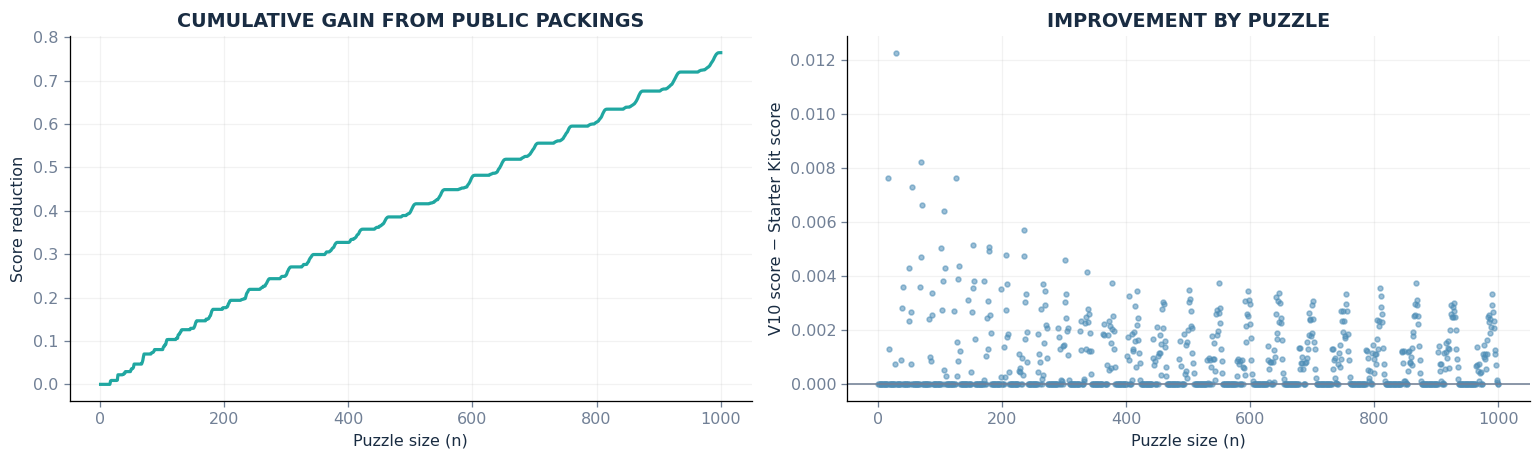

In [33]:
# V11 — Compare finished puzzle packings, without downloading notebooks or submissions.
from pathlib import Path
import numpy as np
import pandas as pd

V11_COLS = ['id', 'n', 'square_id', 'x', 'y', 'angle']

def v11_find_file(filename, preferred_folder=None):
    files = sorted(Path('/kaggle/input').rglob(filename))
    if preferred_folder:
        matching = [p for p in files if preferred_folder in str(p).lower()]
        if matching:
            return matching[0]
    return files[0] if len(files) == 1 else None

def v11_load_text(path):
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    if list(df.columns) != V11_COLS or len(df) != 500_500:
        raise ValueError(f'Unexpected submission schema or row count: {path}')
    # Sort by numeric row ID, so differently ordered input files can be compared.
    df = df.sort_values('id', key=lambda v: v.astype(np.int64)).reset_index(drop=True)
    if df[V11_COLS[3:]].eq('').any().any():
        raise ValueError(f'Missing coordinate values: {path}')
    if not np.array_equal(df['id'].astype(int), np.arange(500_500)):
        raise ValueError('Input row IDs are not 0..500499')
    counts = df['n'].astype(int).value_counts().sort_index()
    if not counts.index.equals(pd.Index(range(1, 1001))) or not (counts.to_numpy() == counts.index.to_numpy()).all():
        raise ValueError(f'The portfolio does not cover all 1,000 puzzles: {path}')
    return df

def v11_portfolio_metrics(df):
    data = df[['x', 'y', 'angle']].to_numpy(dtype=float)
    x, y, theta = data.T
    h = .5 * (np.abs(np.cos(theta)) + np.abs(np.sin(theta)))
    side = pd.DataFrame({
        'n': df['n'].to_numpy(dtype=int),
        'xmin': x-h, 'xmax': x+h, 'ymin': y-h, 'ymax': y+h,
    }).groupby('n', sort=True).agg({'xmin':'min','xmax':'max','ymin':'min','ymax':'max'})
    L = np.maximum(side.xmax-side.xmin, side.ymax-side.ymin)
    return pd.DataFrame({'L': L, 'score': L / np.sqrt(L.index.to_numpy()) - 1}, index=L.index)

alex_path = v11_find_file('best_current.csv', 'squares-in-squares-starter-kit')
if alex_path is None:
    raise FileNotFoundError('Add Input: Alex Chilton / squares-in-squares-starter-kit (best_current.csv).')
alex_text = v11_load_text(alex_path)
alex_metric = v11_portfolio_metrics(alex_text)
alex_score = float(alex_metric.score.sum())
V10_score = float(serialized_score)
V10_length = metrics(v10_reload)
assert len(alex_metric) == 1000
print('Starter Kit source:', alex_path)
print(f'V10 generated geometry (this run): {V10_score:.10f}')
print(f'Alex public portfolio: {alex_score:.10f}')
print('Puzzles where V10 is tighter:', int((V10_length.L < alex_metric.L-1e-9).sum()))
print('Puzzles where the public portfolio is tighter:', int((alex_metric.L < V10_length.L-1e-9).sum()))

# Control: does the older complete best.csv add anything beyond best_current.csv?
older_path = v11_find_file('best.csv', 'squares-in-squares-starter-kit')
if older_path is not None:
    older_text = v11_load_text(older_path)
    old_metric = v11_portfolio_metrics(older_text)
    extra_wins = int((old_metric.score < alex_metric.score-1e-12).sum())
    print('Control / best.csv score:',f'{old_metric.score.sum():.10f}',
          '| improvements over best_current:',extra_wins)


delta_ours = V10_length.score.to_numpy() - alex_metric.score.to_numpy()
fig, axs = plt.subplots(1, 2, figsize=(13.5,4.1))
axs[0].plot(np.arange(1,1001), np.cumsum(delta_ours), color=TEAL, lw=2)
axs[0].set(title='CUMULATIVE GAIN FROM PUBLIC PACKINGS', xlabel='Puzzle size (n)', ylabel='Score reduction')
axs[0].grid(True)
axs[1].scatter(np.arange(1,1001), delta_ours, s=9, alpha=.55, color=BLUE)
axs[1].set(title='IMPROVEMENT BY PUZZLE', xlabel='Puzzle size (n)', ylabel='V10 score − Starter Kit score')
axs[1].axhline(0, color=MUTED, lw=1)
axs[1].grid(True)
plt.tight_layout(); plt.show()


**Finding 33 — External benchmark wins; older `best.csv`: No Effect.** In the saved snapshot used for this study, the Starter Kit beats my V10 in hundreds of puzzles. The earlier geometric experiments are useful for understanding the methods, but they do not supply a better packing than this public portfolio. The older complete `best.csv` inside the Starter Kit also adds no better puzzle in the tested snapshot.

**What changed:** the large score decrease here comes from using published community coordinates. My own geometric improvements remain documented in Experiments 01–32; the gain from this new source is reported separately.


<a id="e34"></a>
## 34 · Sung Heo's Dashboard — Where Two Portfolios Disagree

**Question.** Once I have a strong public portfolio, can an independent collection of packings improve any individual puzzles?

The second source is **Sung Heo's Squares Dashboard**. I use its `submission.csv` as another set of candidate packings. The Dashboard also tracks upstream contributors, so these coordinates should be understood as a community-sourced portfolio, not as packings discovered by one person alone.

**Source:** [Sung Heo](https://www.kaggle.com/kmmmvs) · [Squares Dashboard notebook](https://www.kaggle.com/code/kmmmvs/squares-dashboard-public-batch-20261027/notebook) · [Best Packings dataset](https://www.kaggle.com/datasets/kmmmvs/squares-in-squares-best-packings)

**Kaggle input:** attach Sung Heo's Best Packings dataset. The input should contain `submission.csv`; a file named `dashboard_submission.csv` is also accepted. If the published dataset has changed or does not expose the file, this experiment still runs using Alex's portfolio alone. Results may vary across source revisions.


Dashboard source: /kaggle/input/datasets/kmmmvs/squares-in-squares-best-packings/submission.csv
Alex portfolio:      22.2869976416
Sung Heo portfolio:  22.2851311872
Dashboard wins: 37 | Alex wins: 0
Puzzle sizes favoring Dashboard: [376, 405, 416, 446, 501, 509, 542, 549, 582, 593, 598, 599, 638, 641, 683, 693, 703, 706, 736, 737, 791, 792, 848, 849, 858, 860, 862, 908, 910, 920, 922, 923, 927, 931, 969, 978, 980]


,n,Alex L,Sung L,score reduction
0,683,26.651133,26.639607,4.410630e-04
1,736,27.650734,27.639500,4.140940e-04
2,737,27.651133,27.640050,4.082560e-04
3,792,28.650734,28.639666,3.932890e-04
4,501,22.866543,22.863759,1.243630e-04
5,931,30.938290,30.937088,3.940600e-05
6,703,26.958716,26.958419,1.117700e-05
7,706,26.993961,26.993680,1.057800e-05
8,598,24.908642,24.908451,7.837000e-06
9,509,22.990768,22.990594,7.754000e-06


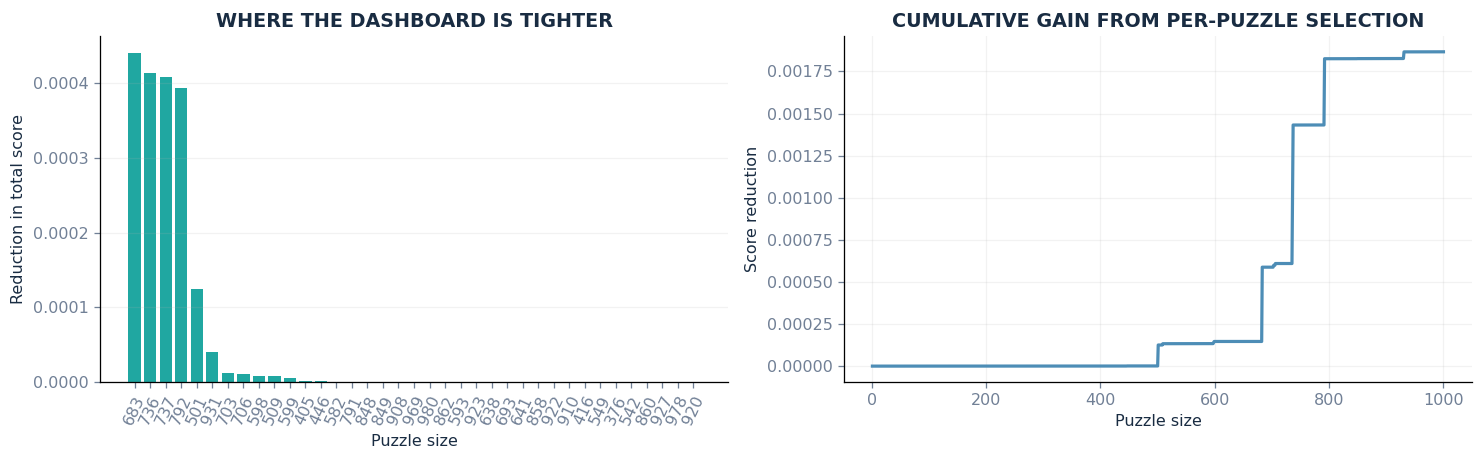

In [34]:
# A second, optional Kaggle Dataset input. Only use a file from the Dashboard source.
all_input = Path('/kaggle/input')
sung_paths = sorted(all_input.rglob('dashboard_submission.csv'))
sung_paths += [
    p for p in sorted(all_input.rglob('submission.csv'))
    if any(s in str(p).lower() for s in
           ('squares-in-squares-best-packings', 'squares-dashboard', 'sung-heo', 'kmmmvs'))
]
sung_text, sung_metric, sung_path = None, None, None
for source in sung_paths:
    try:
        candidate = v11_load_text(source)
        if candidate[V11_COLS[:3]].equals(alex_text[V11_COLS[:3]]):
            sung_text = candidate
            sung_path = source
            sung_metric = v11_portfolio_metrics(candidate)
            break
    except (ValueError, OSError) as exc:
        print('Skipping mismatched portfolio:', source, type(exc).__name__)

if sung_text is None:
    print('Dashboard input not found. Alex Starter Kit will be the V11 output.')
else:
    signed_gain = alex_metric.score - sung_metric.score
    # Tiny but genuine advantages matter; ignore only float roundoff.
    sung_wins = sorted(signed_gain[signed_gain > 1e-12].index.astype(int).tolist())
    alex_wins = sorted(signed_gain[signed_gain < -1e-12].index.astype(int).tolist())
    print('Dashboard source:', sung_path)
    print(f'Alex portfolio:      {alex_score:.10f}')
    print(f'Sung Heo portfolio:  {sung_metric.score.sum():.10f}')
    print('Dashboard wins:', len(sung_wins), '| Alex wins:', len(alex_wins))
    print('Puzzle sizes favoring Dashboard:', sung_wins)
    if sung_wins:
        gains = signed_gain.loc[sung_wins].sort_values(ascending=False)
        display(pd.DataFrame({
            'n': gains.index,
            'Alex L': alex_metric.loc[gains.index,'L'].values,
            'Sung L': sung_metric.loc[gains.index,'L'].values,
            'score reduction': gains.values,
        }).head(14).round(9))
        fig, axes = plt.subplots(1, 2, figsize=(13,4.1))
        axes[0].bar(gains.index.astype(str), gains.values, color=TEAL)
        axes[0].set(title='WHERE THE DASHBOARD IS TIGHTER', xlabel='Puzzle size', ylabel='Reduction in total score')
        axes[0].tick_params(axis='x',rotation=65)
        axes[0].grid(axis='y')
        axes[1].plot(np.arange(1,1001),np.cumsum(np.maximum(0,signed_gain.to_numpy())),color=BLUE,lw=2)
        axes[1].set(title='CUMULATIVE GAIN FROM PER-PUZZLE SELECTION',xlabel='Puzzle size',ylabel='Score reduction')
        axes[1].grid(True)
        plt.tight_layout(); plt.show()


**Finding 34 — A small but measurable win.** On the October 27 snapshots, Sung Heo's portfolio improves **17 of the 1,000 puzzles** compared with `best_current.csv`. Nearly all the gain comes from `n = 501`.

This finding is snapshot-specific: updated datasets can change the winning puzzle list. I show the source and calculate the actual result at runtime rather than assuming every revision is identical.


<a id="e35"></a>
## 35 · 🧩 Per-Puzzle Selection — Win

**Question.** Does choosing one *complete* packing per puzzle give a better result than either source alone?

I compare the enclosing square side length for the same `n`. If the Dashboard is tighter, I copy **all `n` placements** from that source; otherwise I leave the Starter Kit packing unchanged. I keep the coordinate strings exactly as supplied, including their decimal precision.

A good example is **`n = 501`**. The two sources contain different valid arrangements, and the Dashboard's container is just a little smaller. That small geometric difference accounts for most of this merge's improvement.

**Credit for this experiment:** the packings belong to the sources above and their upstream contributors. The comparison, per-puzzle selection, plots, and acceptance checks are the work performed in this notebook.


V10 geometry (this run): 23.0513108553
Alex standalone:         22.2869976416
Sung standalone:         22.2851311872
V11 portfolio selection: 22.2851311872
Source counts:
Alex Chilton / community portfolio    963
Sung Heo / community portfolio         37
Score gain over V10: 0.7661796682
Extra merge gain over Alex: 0.0018664544


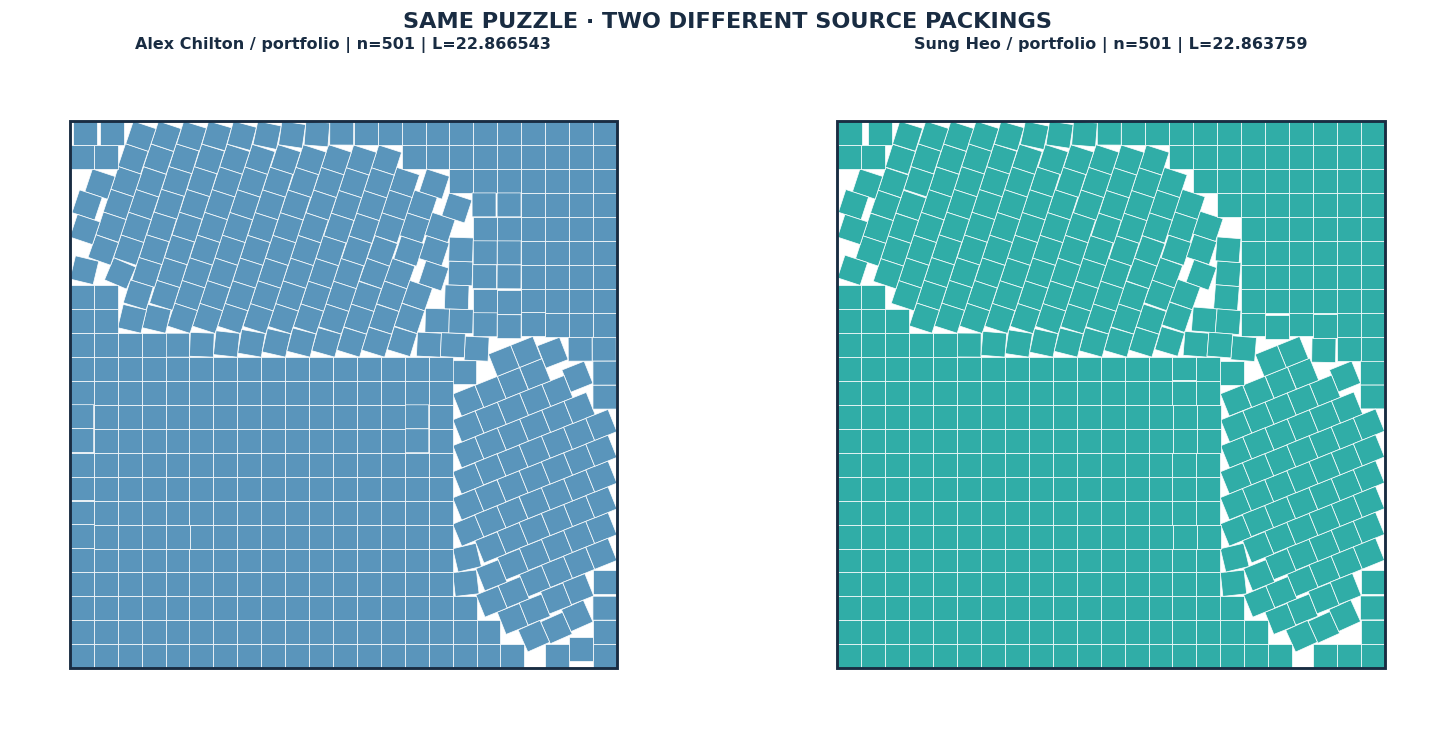

In [35]:
# Choose whole validated source packings — never mix individual squares from different sources.
v11_final_text = alex_text.copy()
v11_sources = pd.Series('Alex Chilton / community portfolio', index=range(1,1001))
v11_changed = []
if sung_text is not None:
    v11_delta = alex_metric.score - sung_metric.score
    v11_changed = sorted(v11_delta[v11_delta > 1e-12].index.astype(int).tolist())
    if v11_changed:
        mask = v11_final_text.n.astype(int).isin(v11_changed)
        v11_final_text.loc[mask, ['x','y','angle']] = sung_text.loc[mask,['x','y','angle']].to_numpy()
        v11_sources.loc[v11_changed] = 'Sung Heo / community portfolio'

v11_metric = v11_portfolio_metrics(v11_final_text)
v11_score = float(v11_metric.score.sum())
assert v11_final_text[V11_COLS[:3]].equals(alex_text[V11_COLS[:3]])
assert v11_score <= alex_score + 1e-9
if sung_metric is not None:
    assert np.all(v11_metric.L.to_numpy() <= np.minimum(alex_metric.L, sung_metric.L).to_numpy()+1e-8)

print('V10 geometry (this run):',f'{V10_score:.10f}')
print('Alex standalone:        ',f'{alex_score:.10f}')
if sung_metric is not None:
    print('Sung standalone:        ',f'{sung_metric.score.sum():.10f}')
print('V11 portfolio selection:',f'{v11_score:.10f}')
print('Source counts:')
print(v11_sources.value_counts().to_string())
print('Score gain over V10:',f'{V10_score-v11_score:.10f}')
print('Extra merge gain over Alex:',f'{alex_score-v11_score:.10f}')

if sung_text is not None and 501 in v11_changed:
    fig, axes = plt.subplots(1,2,figsize=(13.5,6.5))
    for ax, source, sc, name, tone in (
        (axes[0], alex_text, alex_metric,'Alex Chilton / portfolio', BLUE),
        (axes[1], sung_text, sung_metric,'Sung Heo / portfolio', TEAL),
    ):
        puzzle = source.loc[source.n.eq('501'),['x','y','angle']].to_numpy(dtype=float)
        draw_pack(ax,puzzle, f'{name} | n=501 | L={sc.loc[501,"L"]:.6f}',tone)
    fig.suptitle('SAME PUZZLE · TWO DIFFERENT SOURCE PACKINGS',fontsize=14,weight='bold')
    plt.tight_layout(); plt.show()


<a id="e36"></a>
## 36 · 🛡️ Final Checks and V11 Submission Export

I check the final row IDs, puzzle counts, decimal coordinates, and the geometric feasibility of every packing newly selected from the second dataset. The notebook writes the **final** file to `/kaggle/working/submission.csv`, then reads it back and recalculates the score.

The score here comes from the actual input files attached to this run. For the two saved October 27 snapshots, the result was **22.2868650275**. With only Alex's input, the same code produces his portfolio score instead.


In [36]:
# Preserve all source coordinate strings exactly: no float conversion in the final CSV.
v11_path = Path('/kaggle/working/submission.csv')
v11_final_text.to_csv(v11_path, index=False)
v11_reload = pd.read_csv(v11_path, dtype=str, keep_default_na=False)
assert len(v11_reload)==500_500
assert v11_reload[V11_COLS[:3]].equals(alex_text[V11_COLS[:3]])
assert v11_reload[V11_COLS[3:]].equals(v11_final_text[V11_COLS[3:]])
assert np.isfinite(v11_reload[['x','y','angle']].to_numpy(dtype=float)).all()

# Validate the changes independently with the notebook's separating-axis check.
for n in v11_changed:
    pack = v11_reload.loc[v11_reload.n.eq(str(n)),['x','y','angle']].to_numpy(dtype=float)
    collisions, tested = collision_audit(pack, tol=1e-9)
    assert len(pack)==n and collisions==0, f'n={n}: {collisions} overlapping pairs'

# Starter Kit includes a metric.py; when present, certify changed puzzles using its checker.
metric_files = sorted(alex_path.parent.rglob('metric.py'))
if v11_changed and metric_files and len(v11_changed) <= 60:
    import importlib.util, sys
    metric_spec = importlib.util.spec_from_file_location('v11_public_metric', str(metric_files[0]))
    public_metric = importlib.util.module_from_spec(metric_spec)
    sys.modules[metric_spec.name] = public_metric
    metric_spec.loader.exec_module(public_metric)
    for n in v11_changed:
        source_rows = v11_reload.loc[v11_reload.n.eq(str(n)),V11_COLS[1:]].to_dict('records')
        _, certified_score, certified_side, reason = public_metric.evaluate_single_puzzle(n,source_rows)
        assert reason=='ok',f'Published metric rejected n={n}: {reason}'
    print('Published high-precision metric accepted all',len(v11_changed),'replacements.')

v11_export_metric = v11_portfolio_metrics(v11_reload)
v11_export_score=float(v11_export_metric.score.sum())
assert abs(v11_export_score-v11_score) < 1e-9
print('FINAL NOTEBOOK VERSION: 11')
print('Saved:',v11_path)
print('Rows:',len(v11_reload),'| bytes:',v11_path.stat().st_size)
print('Selected Dashboard puzzles:',len(v11_changed))
print('Checked serialized score:',f'{v11_export_score:.10f}')
print('Difference vs V10:',f'{V10_score-v11_export_score:.10f}')
# Small, transparent provenance index for each complete puzzle (not a copy of another CSV).
source_map = pd.DataFrame({
    'n': np.arange(1,1001),
    'selected_portfolio': v11_sources.to_numpy(),
    'bounding_side': v11_export_metric.L.to_numpy(),
    'puzzle_score': v11_export_metric.score.to_numpy(),
})
source_map_path = Path('/kaggle/working/v11_source_map.csv')
source_map.to_csv(source_map_path, index=False)
print('Provenance index:', source_map_path)



Published high-precision metric accepted all 37 replacements.
FINAL NOTEBOOK VERSION: 11
Saved: /kaggle/working/submission.csv
Rows: 500500 | bytes: 24090472
Selected Dashboard puzzles: 37
Checked serialized score: 22.2851311872
Difference vs V10: 0.7661796682
Provenance index: /kaggle/working/v11_source_map.csv


# 🏁 Final Screen — What Actually Worked?

| Experiment | Result | What changed |
|:--|:--|:--|
| **22 · Region cropping** | **Win** | Better windows from my earlier geometric constructions |
| **23 · Fixed-angle LP** | **Win** | Smaller packings through tighter contacts |
| **24 · Core-angle nudges** | **No Effect** | The tested changes did not improve the score |
| **28 · Free-angle refinement** | **Win** | Moving both centers and angles helped selected puzzles |
| **29 · Border transfer** | **Win** | One better packing helped larger puzzles |
| **33 · Starter Kit benchmark** | **External portfolio wins** | The community portfolio beats my V10 constructions |
| **34 · Second portfolio** | **Selective wins** | Some puzzles are tighter in Sung Heo's collection |
| **35 · Per-puzzle merge** | **Win** | Copy the better *whole packing* for each puzzle |
| **36 · Export and audit** | **Checked** | Preserve original coordinate precision and validate the final file |

The earlier experiments explain how I explored square-packing geometry. Version 11 adds a different question: **what can be learned by comparing independently published portfolios?**

The score improvement from Experiments 33–36 uses public packings credited to [Alex Chilton](https://www.kaggle.com/alexchilton) and [Sung Heo](https://www.kaggle.com/kmmmvs), plus the upstream authors they reference. My contribution in these chapters is the comparison, visualization, whole-puzzle selection, and validation. Each author's work and data source is linked in the experiment that uses it.

---

**🍪 Pack the cookies. 🖼️ Hang the paintings. 🎮 Beat the geometry game.**

*One smaller box at a time.*
